In [1]:
import h5py
from pynwb import NWBHDF5IO

nwb_path = "/Users/Sam/dc-allen-data-acquire/data/raw/709401-20231213-v001.nwb"

with NWBHDF5IO(nwb_path, "r") as io:
    nwb = io.read()
    tr = nwb.trials.to_dataframe()

with h5py.File("/Users/Sam/dc-allen-data-acquire/code/python/data/probe_samples/709401-20231213-v001_awake.h5", "r") as f:
    t_start = f.attrs["common_start"]
    t_end = f.attrs["window_end_abs"]
    anchor_t = f.attrs["anchor_time_abs"]

stims = tr[(tr.start_time >= t_start) & (tr.start_time < t_end)]
print(f"Awake Window: {t_start:.2f} s  to  {t_end:.2f} s (Anchor / Iso onset at {anchor_t:.2f} s)")
print("Stimulation trial in window:")
print(stims[["start_time", "stop_time"]])
print(f"Time from stim onset to window start: {stims.iloc[0]['start_time'] - t_start:.2f} s")
print(f"Time from stim onset to window end:   {t_end - stims.iloc[0]['start_time']:.2f} s")

Awake Window: 3070.87 s  to  3190.87 s (Anchor / Iso onset at 3193.87 s)
Stimulation trial in window:
Empty DataFrame
Columns: [start_time, stop_time]
Index: []


IndexError: single positional indexer is out-of-bounds

Project root: /Users/Sam/dc-allen-data-acquire/code/python
Sample Rate: 250.0 Hz
Selected LFP: probeF MOs5 (channel index 147)
Selected EEG Frontal: Ch 13 (MOs)
Selected EEG Soma:    Ch 7 (VISa)


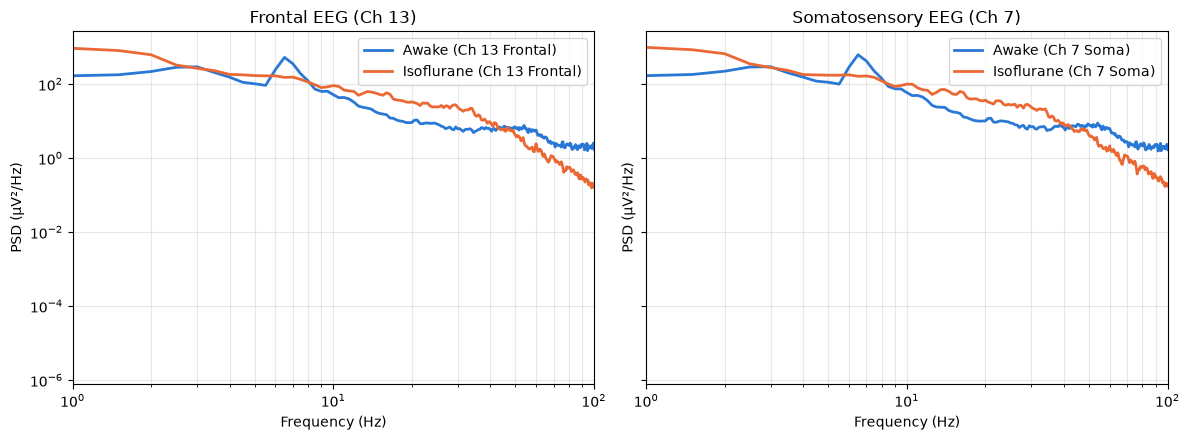

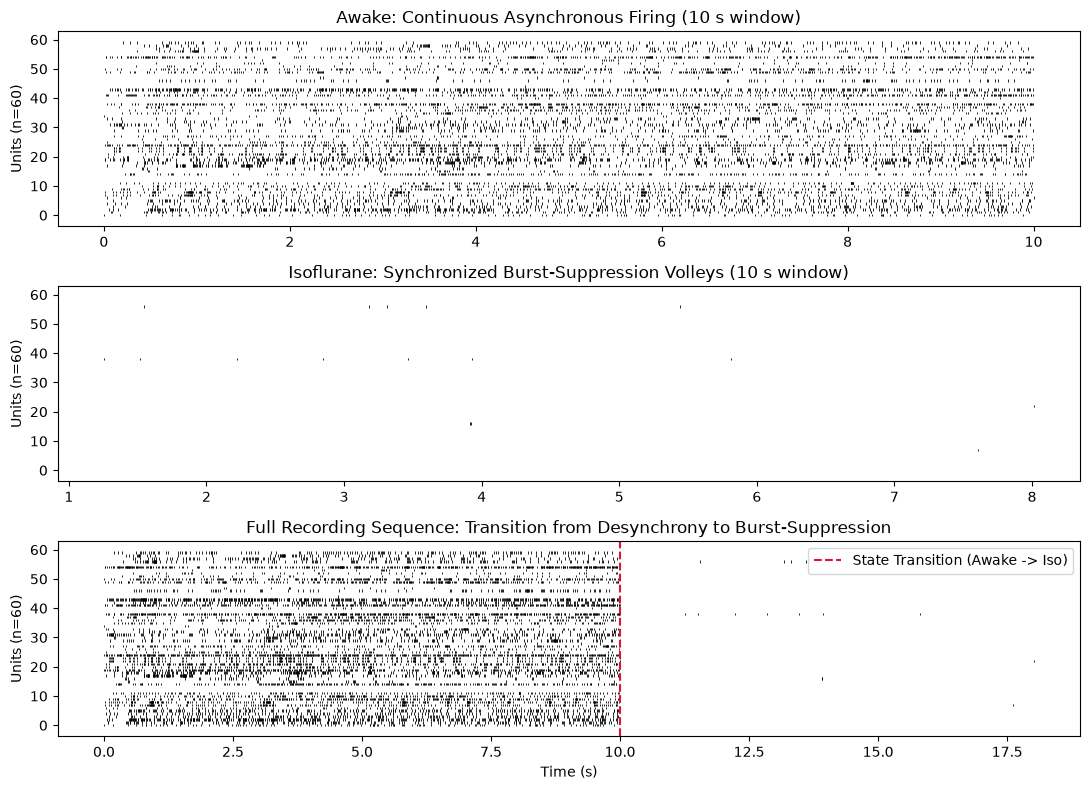


Extracting EEG motifs: Awake
  -> Discovered 1 motif pairs (retained 25001/30001 samples)

Extracting EEG motifs: Isoflurane
  -> Discovered 0 motif pairs (retained 25001/30001 samples)

Extracting EEG motifs: Full/Combined
  -> Discovered 1 motif pairs (retained 55002/60002 samples)


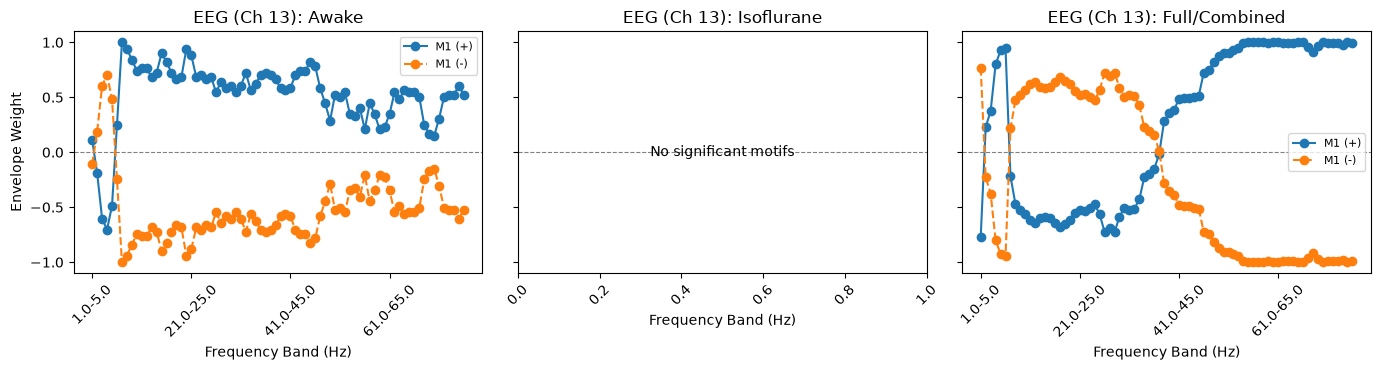


Extracting LFP motifs: Awake
  -> Discovered 1 motif pairs (retained 25001/30001 samples)

Extracting LFP motifs: Isoflurane
  -> Discovered 0 motif pairs (retained 25001/30001 samples)

Extracting LFP motifs: Full/Combined
  -> Discovered 1 motif pairs (retained 55002/60002 samples)


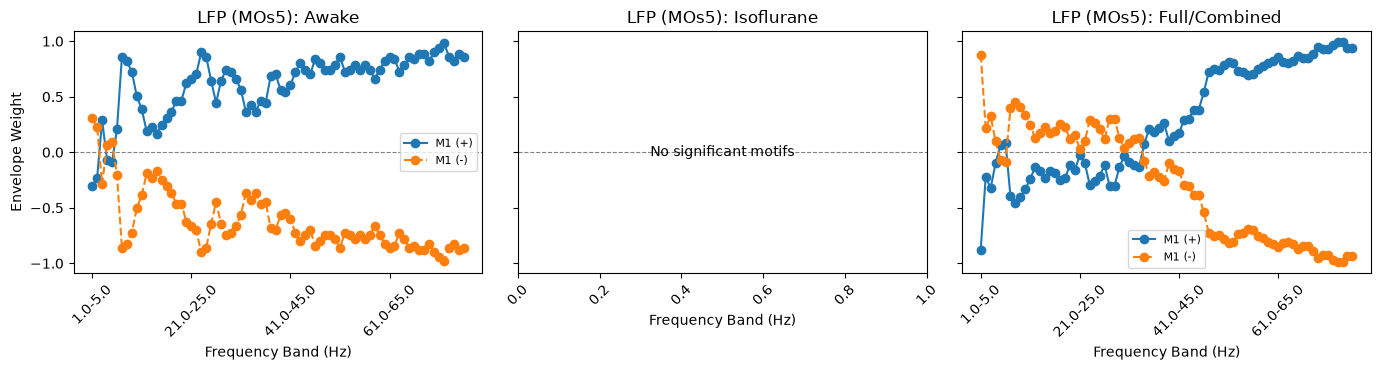

In [3]:
# %% [markdown]
# # Cross-State Electrophysiology: EEG vs. LFP Motifs & Spectra
# Comparing Awake Only, Isoflurane Only, and Full/Combined recording.

# %%
import os
import sys
from pathlib import Path
import h5py
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
from pynwb import NWBHDF5IO
from scipy import signal

# -------------------------------------------------------------------------
# PATH ANCHORING
# -------------------------------------------------------------------------
# Walk up directory tree until the root folder containing 'data' is found
curr = Path.cwd().resolve()
root_dir = None
for p in [curr, *curr.parents]:
    if (p / "data").is_dir():
        root_dir = p
        break

if root_dir is None:
    raise FileNotFoundError("Could not find project root containing the 'data' directory.")

# Ensure 'src' is importable
src_parent = root_dir / "code" / "python"
if not (src_parent / "src").is_dir():
    src_parent = root_dir  # fallback if src sits directly under root

if str(src_parent) not in sys.path:
    sys.path.insert(0, str(src_parent))

from src.get_motifs import get_motifs
from src.smooth_env import DEFAULT_FREQ_BANDS, smooth_env

# Configuration paths anchored to project root
DATA_DIR = root_dir / "data" / "probe_samples"
RAW_NWB = root_dir / "data" / "raw" / "709401-20231213-v001.nwb"
SESSION = "709401-20231213-v001"
BANDS = DEFAULT_FREQ_BANDS

# -------------------------------------------------------------------------
# 1. LOAD EXTRACTED 2-MIN WINDOWS (Awake & Isoflurane)
# -------------------------------------------------------------------------
awake_path = DATA_DIR / f"{SESSION}_awake.h5"
iso_path = DATA_DIR / f"{SESSION}_iso_anesthetized.h5"

if not awake_path.exists():
    raise FileNotFoundError(f"Awake file not found: {awake_path}")
if not iso_path.exists():
    raise FileNotFoundError(f"Isoflurane file not found: {iso_path}")

with h5py.File(awake_path, "r") as fa:
    fs = float(fa.attrs["fs"])
    awake_eeg = fa["eeg/data"][:]
    awake_lfp = fa["lfp/data"][:]
    eeg_locs = fa["eeg/location"][:].astype(str)
    lfp_locs = fa["lfp/location"][:].astype(str)
    lfp_probes = fa["lfp/probe"][:].astype(str)
    awake_spikes = {
        "times": fa["spikes/times"][:],
        "index": fa["spikes/index"][:],
        "location": fa["spikes/location"][:].astype(str),
        "y": fa["spikes/y"][:],
    }

with h5py.File(iso_path, "r") as fi:
    iso_eeg = fi["eeg/data"][:]
    iso_lfp = fi["lfp/data"][:]
    iso_spikes = {
        "times": fi["spikes/times"][:],
        "index": fi["spikes/index"][:],
        "location": fi["spikes/location"][:].astype(str),
        "y": fi["spikes/y"][:],
    }

# -------------------------------------------------------------------------
# 2. CHANNEL SELECTION (EEG & Deep LFP)
# -------------------------------------------------------------------------
# Frontal EEG = Channel 13; Somatosensory EEG = Channel 7
eeg_frontal_idx = 13
eeg_soma_idx = 7

# Deep LFP: Target MOs5 or MOs6a on probeF
lfp_match = np.where((lfp_locs == "MOs5") & (lfp_probes == "probeF"))[0]
if len(lfp_match) == 0:
    lfp_match = np.where((lfp_locs == "MOs6a") & (lfp_probes == "probeF"))[0]
if len(lfp_match) == 0:
    # Fallback to any probeF channel starting with MOs
    lfp_match = np.where([loc.startswith("MOs") and p == "probeF" for loc, p in zip(lfp_locs, lfp_probes)])[0]

lfp_deep_idx = lfp_match[0]
print(f"Project root: {root_dir}")
print(f"Sample Rate: {fs} Hz")
print(f"Selected LFP: {lfp_probes[lfp_deep_idx]} {lfp_locs[lfp_deep_idx]} (channel index {lfp_deep_idx})")
print(f"Selected EEG Frontal: Ch {eeg_frontal_idx} ({eeg_locs[eeg_frontal_idx]})")
print(f"Selected EEG Soma:    Ch {eeg_soma_idx} ({eeg_locs[eeg_soma_idx]})")

# Signal dictionaries across states
sig_eeg = {
    "Awake": awake_eeg[:, eeg_frontal_idx],
    "Isoflurane": iso_eeg[:, eeg_frontal_idx],
    "Full/Combined": np.concatenate([awake_eeg[:, eeg_frontal_idx], iso_eeg[:, eeg_frontal_idx]]),
}

sig_lfp = {
    "Awake": awake_lfp[:, lfp_deep_idx],
    "Isoflurane": iso_lfp[:, lfp_deep_idx],
    "Full/Combined": np.concatenate([awake_lfp[:, lfp_deep_idx], iso_lfp[:, lfp_deep_idx]]),
}

# %% [markdown]
# ## 1. Power Spectrum Analysis (EEG & LFP)
# Welch PSD across states for Frontal EEG Ch 13 and Somatosensory Ch 7.

# %%
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)

for name, col in zip(["Awake", "Isoflurane"], ["#2a78d6", "#eb6834"]):
    data = awake_eeg if name == "Awake" else iso_eeg

    # Frontal (Ch 13)
    f_fr, p_fr = signal.welch(data[:, eeg_frontal_idx], fs=fs, nperseg=int(2 * fs))
    axes[0].plot(
        f_fr, p_fr, color=col, lw=2, label=f"{name} (Ch 13 Frontal)"
    )

    # Somatosensory (Ch 7)
    f_so, p_so = signal.welch(data[:, eeg_soma_idx], fs=fs, nperseg=int(2 * fs))
    axes[1].plot(
        f_so, p_so, color=col, lw=2, label=f"{name} (Ch 7 Soma)"
    )

for ax, title in zip(
    axes, ["Frontal EEG (Ch 13)", "Somatosensory EEG (Ch 7)"]
):
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(1, 100)
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel("PSD (µV²/Hz)")
    ax.set_title(title)
    ax.legend()
    ax.grid(True, which="both", alpha=0.3)

plt.tight_layout()
plt.show()

# %% [markdown]
# ## 2. Spike Raster Plots: Awake, Isoflurane, and Continuous Transition
# Visualizing unit firing patterns across all three state conditions.

# %%
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=False)


def plot_unit_raster(ax, spike_dict, title, t_start=0.0, t_dur=10.0):
    starts = np.concatenate([[0], spike_dict["index"][:-1]])
    trains = []
    n_units = min(len(spike_dict["index"]), 60)
    for r in range(n_units):
        st = spike_dict["times"][starts[r] : spike_dict["index"][r]]
        # Filter spikes inside display window
        trains.append(st[(st >= t_start) & (st < t_start + t_dur)] - t_start)
    ax.eventplot(trains, colors="black", linewidths=0.6, linelengths=0.8)
    ax.set_title(title)
    ax.set_ylabel(f"Units (n={n_units})")


# 1. Awake Window (10 s snapshot)
plot_unit_raster(
    axes[0],
    awake_spikes,
    "Awake: Continuous Asynchronous Firing (10 s window)",
    t_start=0.0,
    t_dur=10.0,
)

# 2. Isoflurane Window (10 s snapshot)
plot_unit_raster(
    axes[1],
    iso_spikes,
    "Isoflurane: Synchronized Burst-Suppression Volleys (10 s window)",
    t_start=0.0,
    t_dur=10.0,
)

# 3. Full / Combined State Comparison (Concatenated Awake -> Isoflurane)
# Showing a 20 s snippet (10 s Awake followed by 10 s Isoflurane)
starts_aw = np.concatenate([[0], awake_spikes["index"][:-1]])
starts_iso = np.concatenate([[0], iso_spikes["index"][:-1]])
n_units = min(len(awake_spikes["index"]), 60)
combined_trains = []

for r in range(n_units):
    st_aw = awake_spikes["times"][starts_aw[r] : awake_spikes["index"][r]]
    st_aw = st_aw[(st_aw >= 0) & (st_aw < 10.0)]

    st_iso = iso_spikes["times"][starts_iso[r] : iso_spikes["index"][r]]
    st_iso = st_iso[(st_iso >= 0) & (st_iso < 10.0)] + 10.0  # offset by 10s

    combined_trains.append(np.concatenate([st_aw, st_iso]))

axes[2].eventplot(
    combined_trains, colors="black", linewidths=0.6, linelengths=0.8
)
axes[2].axvline(
    10.0,
    color="crimson",
    linestyle="--",
    lw=1.5,
    label="State Transition (Awake -> Iso)",
)
axes[2].set_title(
    "Full Recording Sequence: Transition from Desynchrony to Burst-Suppression"
)
axes[2].set_xlabel("Time (s)")
axes[2].set_ylabel(f"Units (n={n_units})")
axes[2].legend(loc="upper right")

plt.tight_layout()
plt.show()

# %% [markdown]
# ## 3. EEG Motif Discovery (Ch 13 Frontal)
# Running smooth_env + get_motifs on: Awake only, Iso only, and Combined.

# %%
eeg_motifs = {}
band_names = [f"{lo}-{hi}" for lo, hi in BANDS]

for state, x in sig_eeg.items():
    print(f"\nExtracting EEG motifs: {state}")
    env = smooth_env(x, fs, BANDS)

    #dimension check
    if env.shape[0] > env.shape[1]:
        env = env.T
    
    # Trim NaN edges produced by smooth_env filtering
    valid_cols = np.all(np.isfinite(env), axis=0)
    env_clean = env[:, valid_cols]
    
    res = get_motifs([env_clean], fs, n_null=20, seed=0, verbose=False)
    eeg_motifs[state] = res
    print(f"  -> Discovered {res.n_motifs} motif pairs (retained {env_clean.shape[1]}/{env.shape[1]} samples)")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, (state, res) in zip(axes, eeg_motifs.items()):
    ax.axhline(0, color="gray", lw=0.8, ls="--")
    if res.n_motifs > 0:
        for i in range(res.n_motifs):
            ax.plot(band_names, res.motifs[:, i], "-o", label=f"M{i+1} (+)")
            ax.plot(band_names, res.motifs[:, i + res.n_motifs], "--o", label=f"M{i+1} (-)")
        ax.legend(fontsize=8)
    else:
        ax.text(0.5, 0.5, "No significant motifs", ha="center", va="center", transform=ax.transAxes)
    ax.set_title(f"EEG (Ch 13): {state}")
    ax.tick_params(axis="x", rotation=45)
    ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=5))
    ax.set_xlabel("Frequency Band (Hz)")

axes[0].set_ylabel("Envelope Weight")
plt.tight_layout()
plt.show()

# %% [markdown]
# ## 4. LFP Motif Discovery (Deep MOs)
# Running smooth_env + get_motifs on: Awake only, Iso only, and Combined.

# %%
lfp_motifs = {}

for state, x in sig_lfp.items():
    print(f"\nExtracting LFP motifs: {state}")
    env = smooth_env(x, fs, BANDS)
    
    #dimension check
    if env.shape[0] > env.shape[1]:
        env = env.T
    
    # Trim NaN edges produced by smooth_env filtering
    valid_cols = np.all(np.isfinite(env), axis=0)
    env_clean = env[:, valid_cols]
    
    res = get_motifs([env_clean], fs, n_null=20, seed=0, verbose=False)
    lfp_motifs[state] = res
    print(f"  -> Discovered {res.n_motifs} motif pairs (retained {env_clean.shape[1]}/{env.shape[1]} samples)")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, (state, res) in zip(axes, lfp_motifs.items()):
    ax.axhline(0, color="gray", lw=0.8, ls="--")
    if res.n_motifs > 0:
        for i in range(res.n_motifs):
            ax.plot(band_names, res.motifs[:, i], "-o", label=f"M{i+1} (+)")
            ax.plot(band_names, res.motifs[:, i + res.n_motifs], "--o", label=f"M{i+1} (-)")
        ax.legend(fontsize=8)
    else:
        ax.text(0.5, 0.5, "No significant motifs", ha="center", va="center", transform=ax.transAxes)
    ax.set_title(f"LFP ({lfp_locs[lfp_deep_idx]}): {state}")
    ax.tick_params(axis="x", rotation=45)
    ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=5))
    ax.set_xlabel("Frequency Band (Hz)")

axes[0].set_ylabel("Envelope Weight")
plt.tight_layout()
plt.show()


================ Running Step 5 for: Awake ================
  Motif 1:
    Component A (LFP vs EEG proj) r = 0.949 (p = 1.9960e-03)
    Component B (LFP vs EEG proj) r = 0.949
    Cross-Opponent (LFP A vs EEG B) r = -0.949 (Expect negative)

================ Running Step 5 for: Isoflurane ================
Skipping Isoflurane: No LFP motifs found.

================ Running Step 5 for: Full/Combined ================
  Motif 1:
    Component A (LFP vs EEG proj) r = 0.891 (p = 1.9960e-03)
    Component B (LFP vs EEG proj) r = 0.891
    Cross-Opponent (LFP A vs EEG B) r = -0.891 (Expect negative)


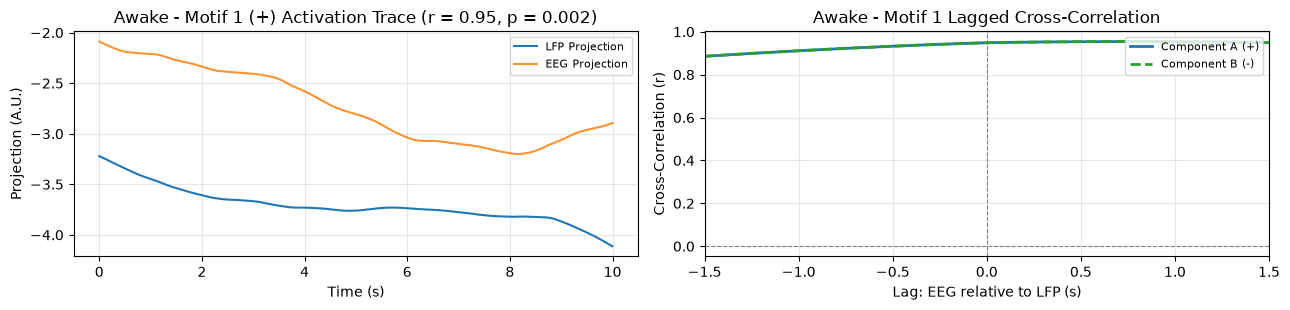

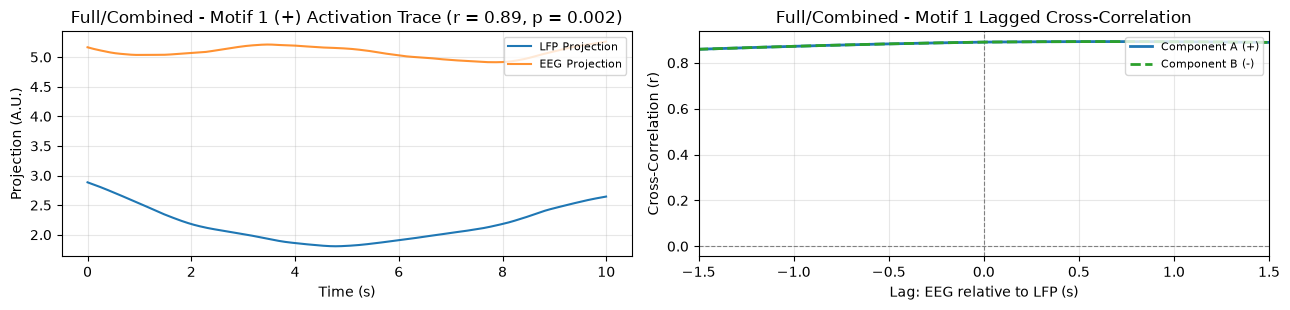

In [4]:
# %% [markdown]
# ## 5. Cross-Modal Dynamic Motif Projections (Step 5)
# Projecting instantaneous EEG envelopes onto LFP motifs and vice versa.

# %%
def get_clean_envelopes(sig, fs, bands):
    """Compute normalized, zero-mean smoothed multi-frequency envelopes."""
    env = smooth_env(sig, fs, bands)
    if env.shape[0] > env.shape[1]:
        env = env.T  # Shape: [n_bands, n_samples]
    return env

def compute_motif_projections(env, motif_templates):
    """
    Project instantaneous normalized multi-frequency envelopes onto motif templates.
    env: [n_bands, n_samples]
    motif_templates: [n_bands, n_templates]
    Returns: projections of shape [n_templates, n_samples]
    """
    # z-score bands across time to evaluate relative fluctuations (following Mishler et al.)
    env_norm = (env - np.nanmean(env, axis=1, keepdims=True)) / np.nanstd(env, axis=1, keepdims=True)
    
    # Normalize motif templates to unit length
    template_norms = np.linalg.norm(motif_templates, axis=0, keepdims=True)
    template_norms[template_norms == 0] = 1.0
    templates_unit = motif_templates / template_norms
    
    # Linear projection: [n_templates, n_bands] @ [n_bands, n_samples]
    projections = templates_unit.T @ env_norm
    return projections

def cross_correlate_max_lag(x, y, max_lag_samples):
    """Compute normalized cross-correlation across lags: [-max_lag, +max_lag]."""
    x_zm = x - np.mean(x)
    y_zm = y - np.mean(y)
    denom = np.sqrt(np.sum(x_zm**2) * np.sum(y_zm**2))
    if denom == 0:
        return np.zeros(2 * max_lag_samples + 1)
    
    corr_full = signal.correlate(x_zm, y_zm, mode='full') / denom
    mid = len(corr_full) // 2
    return corr_full[mid - max_lag_samples : mid + max_lag_samples + 1]


# -------------------------------------------------------------------------
# RUN PROJECTION ANALYSIS ACROSS RECORDING STATES
# -------------------------------------------------------------------------
results_projection = {}

for state in ["Awake", "Isoflurane", "Full/Combined"]:
    print(f"\n================ Running Step 5 for: {state} ================")
    lfp_res = lfp_motifs[state]
    eeg_res = eeg_motifs[state]
    
    if lfp_res.n_motifs == 0:
        print(f"Skipping {state}: No LFP motifs found.")
        continue

    # Extract temporal envelopes for both modalities
    env_lfp = get_clean_envelopes(sig_lfp[state], fs, BANDS)
    env_eeg = get_clean_envelopes(sig_eeg[state], fs, BANDS)
    
    # Ensure exact same sample length and mask finite values across both
    min_len = min(env_lfp.shape[1], env_eeg.shape[1])
    env_lfp = env_lfp[:, :min_len]
    env_eeg = env_eeg[:, :min_len]
    
    valid_mask = np.all(np.isfinite(env_lfp), axis=0) & np.all(np.isfinite(env_eeg), axis=0)
    env_lfp_clean = env_lfp[:, valid_mask]
    env_eeg_clean = env_eeg[:, valid_mask]
    
    # 1. Native LFP Projections: [n_templates, n_samples]
    proj_lfp_native = compute_motif_projections(env_lfp_clean, lfp_res.motifs)
    
    # 2. Cross-Modal Projections: Project EEG envelopes onto LFP motif templates
    proj_eeg_on_lfp = compute_motif_projections(env_eeg_clean, lfp_res.motifs)
    
    n_pairs = lfp_res.n_motifs
    max_lag_sec = 2.0
    max_lag_samples = int(max_lag_sec * fs)
    lags = np.arange(-max_lag_samples, max_lag_samples + 1) / fs
    
    state_corrs = []
    
    for i in range(n_pairs):
        # Index i is (+) component (Motif A); index i + n_pairs is (-) opponent component (Motif B)
        idx_A = i
        idx_B = i + n_pairs
        
        # Zero-lag Pearson correlations
        r_A = np.corrcoef(proj_lfp_native[idx_A], proj_eeg_on_lfp[idx_A])[0, 1]
        r_B = np.corrcoef(proj_lfp_native[idx_B], proj_eeg_on_lfp[idx_B])[0, 1]
        r_cross = np.corrcoef(proj_lfp_native[idx_A], proj_eeg_on_lfp[idx_B])[0, 1]
        
        # Lagged cross-correlation curve
        cc_A = cross_correlate_max_lag(proj_lfp_native[idx_A], proj_eeg_on_lfp[idx_A], max_lag_samples)
        cc_B = cross_correlate_max_lag(proj_lfp_native[idx_B], proj_eeg_on_lfp[idx_B], max_lag_samples)
        
        # --- CIRCULAR TIME-SHIFT NULL (Step 7 validation) ---
        n_shifts = 500
        null_r = np.zeros(n_shifts)
        T = proj_eeg_on_lfp.shape[1]
        min_shift = int(5.0 * fs)  # minimum 5-second circular shift
        
        for s in range(n_shifts):
            shift = np.random.randint(min_shift, T - min_shift)
            shifted_eeg_proj = np.roll(proj_eeg_on_lfp[idx_A], shift)
            null_r[s] = np.corrcoef(proj_lfp_native[idx_A], shifted_eeg_proj)[0, 1]
            
        p_val_A = (1.0 + np.sum(np.abs(null_r) >= np.abs(r_A))) / (n_shifts + 1)
        
        state_corrs.append({
            "motif_idx": i + 1,
            "r_A": r_A,
            "r_B": r_B,
            "r_cross_opp": r_cross,
            "p_val_A": p_val_A,
            "cc_A": cc_A,
            "cc_B": cc_B
        })
        
        print(f"  Motif {i+1}:")
        print(f"    Component A (LFP vs EEG proj) r = {r_A:.3f} (p = {p_val_A:.4e})")
        print(f"    Component B (LFP vs EEG proj) r = {r_B:.3f}")
        print(f"    Cross-Opponent (LFP A vs EEG B) r = {r_cross:.3f} (Expect negative)")
        
    results_projection[state] = {
        "lags": lags,
        "metrics": state_corrs,
        "proj_lfp": proj_lfp_native,
        "proj_eeg": proj_eeg_on_lfp
    }

# %% [markdown]
# ## 6. Visualizing Cross-Modal Concordance & Lag Dynamics
# Plotting temporal tracking and lag curves.

# %%
for state, res in results_projection.items():
    metrics = res["metrics"]
    lags = res["lags"]
    n_motifs = len(metrics)
    
    if n_motifs == 0:
        continue
        
    fig, axes = plt.subplots(n_motifs, 2, figsize=(13, 3.2 * n_motifs), squeeze=False)
    
    t_plot_sec = 10.0
    n_plot_samples = int(t_plot_sec * fs)
    t_vec = np.arange(n_plot_samples) / fs
    
    for row, m in enumerate(metrics):
        m_num = m["motif_idx"]
        idx_A = m_num - 1
        
        # Col 1: Time series tracking (10 s window)
        ax_t = axes[row, 0]
        ax_t.plot(t_vec, res["proj_lfp"][idx_A, :n_plot_samples], color="#1f77b4", lw=1.5, label="LFP Projection")
        ax_t.plot(t_vec, res["proj_eeg"][idx_A, :n_plot_samples], color="#ff7f0e", lw=1.5, alpha=0.85, label="EEG Projection")
        ax_t.set_title(f"{state} - Motif {m_num} (+) Activation Trace (r = {m['r_A']:.2f}, p = {m['p_val_A']:.3f})")
        ax_t.set_xlabel("Time (s)")
        ax_t.set_ylabel("Projection (A.U.)")
        ax_t.legend(loc="upper right", fontsize=8)
        ax_t.grid(True, alpha=0.3)
        
        # Col 2: Cross-Correlation Lag Curve
        ax_l = axes[row, 1]
        ax_l.axvline(0, color="gray", ls="--", lw=0.8)
        ax_l.axhline(0, color="gray", ls="--", lw=0.8)
        ax_l.plot(lags, m["cc_A"], color="#1f77b4", lw=2, label="Component A (+)")
        ax_l.plot(lags, m["cc_B"], color="#2ca02c", lw=2, ls="--", label="Component B (-)")
        ax_l.set_title(f"{state} - Motif {m_num} Lagged Cross-Correlation")
        ax_l.set_xlabel("Lag: EEG relative to LFP (s)")
        ax_l.set_ylabel("Cross-Correlation (r)")
        ax_l.set_xlim(-1.5, 1.5)
        ax_l.legend(loc="upper right", fontsize=8)
        ax_l.grid(True, alpha=0.3)
        
    plt.tight_layout()
    plt.show()

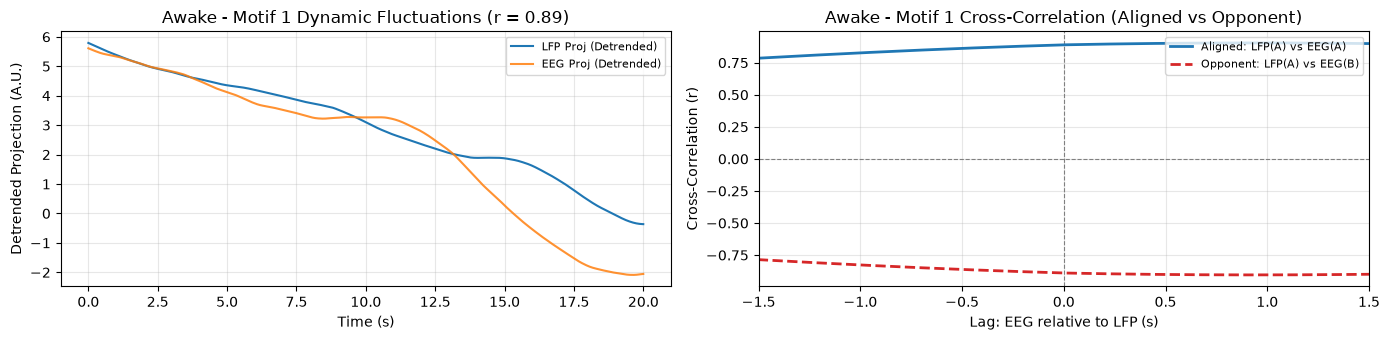

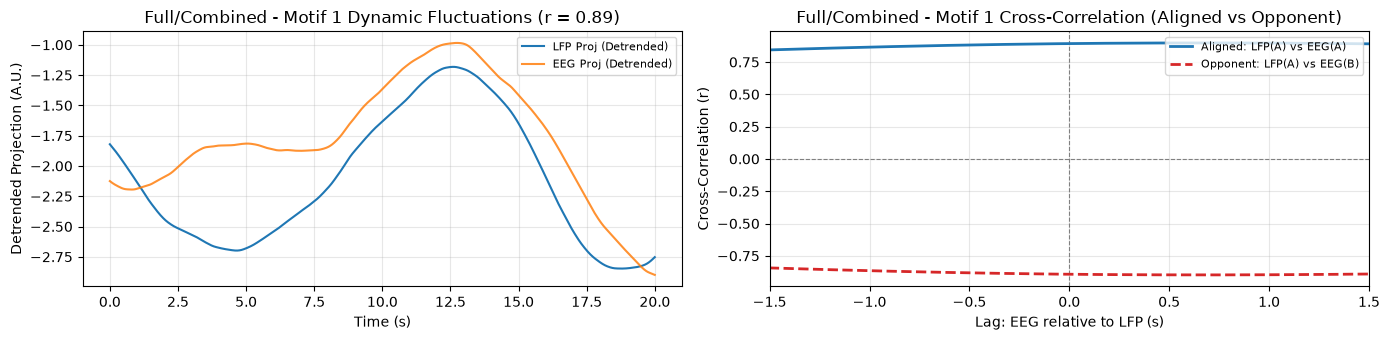

In [5]:
# %% [markdown]
# ## 5 (Revised). Dynamic Cross-Modal Motif Projections & Detrended Lag Analysis

# %%
from scipy.signal import detrend

results_projection = {}

for state in ["Awake", "Full/Combined"]:
    lfp_res = lfp_motifs[state]
    eeg_res = eeg_motifs[state]
    
    if lfp_res.n_motifs == 0:
        continue

    env_lfp = get_clean_envelopes(sig_lfp[state], fs, BANDS)
    env_eeg = get_clean_envelopes(sig_eeg[state], fs, BANDS)
    
    min_len = min(env_lfp.shape[1], env_eeg.shape[1])
    env_lfp = env_lfp[:, :min_len]
    env_eeg = env_eeg[:, :min_len]
    
    valid_mask = np.all(np.isfinite(env_lfp), axis=0) & np.all(np.isfinite(env_eeg), axis=0)
    env_lfp_clean = env_lfp[:, valid_mask]
    env_eeg_clean = env_eeg[:, valid_mask]
    
    # 1. Compute projections
    proj_lfp = compute_motif_projections(env_lfp_clean, lfp_res.motifs)
    proj_eeg = compute_motif_projections(env_eeg_clean, lfp_res.motifs)
    
    # 2. DETREND to eliminate 2-minute baseline drift artifacts
    proj_lfp_dt = detrend(proj_lfp, axis=1)
    proj_eeg_dt = detrend(proj_eeg, axis=1)
    
    n_pairs = lfp_res.n_motifs
    max_lag_sec = 2.0
    max_lag_samples = int(max_lag_sec * fs)
    lags = np.arange(-max_lag_samples, max_lag_samples + 1) / fs
    
    state_corrs = []
    
    for i in range(n_pairs):
        idx_A = i
        idx_B = i + n_pairs
        
        # Zero-lag correlations on detrended projections
        r_A = np.corrcoef(proj_lfp_dt[idx_A], proj_eeg_dt[idx_A])[0, 1]
        r_cross = np.corrcoef(proj_lfp_dt[idx_A], proj_eeg_dt[idx_B])[0, 1]
        
        # 1. Aligned Cross-Correlation: LFP(A) vs EEG(A) -> EXPECT POSITIVE PEAK AT LAG 0
        cc_aligned = cross_correlate_max_lag(proj_lfp_dt[idx_A], proj_eeg_dt[idx_A], max_lag_samples)
        
        # 2. Opponent Cross-Correlation: LFP(A) vs EEG(B) -> EXPECT NEGATIVE TROUGH AT LAG 0
        cc_opponent = cross_correlate_max_lag(proj_lfp_dt[idx_A], proj_eeg_dt[idx_B], max_lag_samples)
        
        state_corrs.append({
            "motif_idx": i + 1,
            "r_A": r_A,
            "r_cross": r_cross,
            "cc_aligned": cc_aligned,
            "cc_opponent": cc_opponent,
        })
        
    results_projection[state] = {
        "lags": lags,
        "metrics": state_corrs,
        "proj_lfp_raw": proj_lfp,
        "proj_eeg_raw": proj_eeg,
        "proj_lfp_dt": proj_lfp_dt,
        "proj_eeg_dt": proj_eeg_dt,
    }

# %%
# Visualizing Detrended Dynamics
for state, res in results_projection.items():
    metrics = res["metrics"]
    lags = res["lags"]
    n_motifs = len(metrics)
    
    fig, axes = plt.subplots(n_motifs, 2, figsize=(14, 3.5 * n_motifs), squeeze=False)
    
    # Show first 20 seconds
    t_plot_sec = 20.0
    n_plot_samples = int(t_plot_sec * fs)
    t_vec = np.arange(n_plot_samples) / fs
    
    for row, m in enumerate(metrics):
        m_num = m["motif_idx"]
        idx_A = m_num - 1
        
        # Col 1: Detrended time series (shows actual oscillatory modulation)
        ax_t = axes[row, 0]
        ax_t.plot(t_vec, res["proj_lfp_dt"][idx_A, :n_plot_samples], color="#1f77b4", lw=1.5, label="LFP Proj (Detrended)")
        ax_t.plot(t_vec, res["proj_eeg_dt"][idx_A, :n_plot_samples], color="#ff7f0e", lw=1.5, alpha=0.85, label="EEG Proj (Detrended)")
        ax_t.set_title(f"{state} - Motif {m_num} Dynamic Fluctuations (r = {m['r_A']:.2f})")
        ax_t.set_xlabel("Time (s)")
        ax_t.set_ylabel("Detrended Projection (A.U.)")
        ax_t.legend(loc="upper right", fontsize=8)
        ax_t.grid(True, alpha=0.3)
        
        # Col 2: Aligned vs Opponent Cross-Correlation
        ax_l = axes[row, 1]
        ax_l.axvline(0, color="gray", ls="--", lw=0.8)
        ax_l.axhline(0, color="gray", ls="--", lw=0.8)
        ax_l.plot(lags, m["cc_aligned"], color="#1f77b4", lw=2, label="Aligned: LFP(A) vs EEG(A)")
        ax_l.plot(lags, m["cc_opponent"], color="#d62728", lw=2, ls="--", label="Opponent: LFP(A) vs EEG(B)")
        ax_l.set_title(f"{state} - Motif {m_num} Cross-Correlation (Aligned vs Opponent)")
        ax_l.set_xlabel("Lag: EEG relative to LFP (s)")
        ax_l.set_ylabel("Cross-Correlation (r)")
        ax_l.set_xlim(-1.5, 1.5)
        ax_l.legend(loc="upper right", fontsize=8)
        ax_l.grid(True, alpha=0.3)
        
    plt.tight_layout()
    plt.show()

In [6]:
# %% [markdown]
# # Option A: Long Continuous NWB Extraction & Motif Validation
# Extracting a continuous 10-minute epoch from the raw NWB to overcome smoothing artifacts.

# %%
from pynwb import NWBHDF5IO
import numpy as np
from scipy import signal
from scipy.signal import detrend
import matplotlib.pyplot as plt
from pathlib import Path

# -------------------------------------------------------------------------
# 1. LOAD CONTINUOUS 10-MINUTE EPOCH FROM RAW NWB
# -------------------------------------------------------------------------
nwb_path = Path("/Users/Sam/dc-allen-data-acquire/data/raw/709401-20231213-v001.nwb")

if not nwb_path.exists():
    raise FileNotFoundError(f"File not found at: {nwb_path}")

duration_sec = 600.0  # 10 minutes of continuous data
start_time_sec = 0.0  # Adjust if the awake period starts later in the recording

print(f"Checking path: {nwb_path}")
if not nwb_path.exists():
    raise FileNotFoundError(f"You must download or locate the raw NWB file. It is not at: {nwb_path}")

print(f"Opening NWB file: {nwb_path}")
with NWBHDF5IO(nwb_path, 'r') as io:
    nwb = io.read()
    
    # 1a. Locate the EEG and LFP electrical series in the NWB structure
    # (Adjust the keys below if your NWB stores them in different acquisition/processing nodes)
    if 'EEG' in nwb.acquisition:
        eeg_series = nwb.acquisition['EEG']
    else:
        # Fallback if named differently
        eeg_keys = [k for k in nwb.acquisition.keys() if 'eeg' in k.lower()]
        eeg_series = nwb.acquisition[eeg_keys[0]]

    # Deep LFP is typically in processing/ecephys, but sometimes in acquisition
    if 'ecephys' in nwb.processing and 'LFP' in nwb.processing['ecephys'].data_interfaces:
        lfp_series = nwb.processing['ecephys'].data_interfaces['LFP'].electrical_series['LFP']
    else:
        lfp_keys = [k for k in nwb.acquisition.keys() if 'lfp' in k.lower()]
        lfp_series = nwb.acquisition[lfp_keys[0]]
        
    # If lfp_series resolved to the pynwb.ecephys.LFP container:
    if hasattr(lfp_series, "electrical_series"):
        # Grab the first available ElectricalSeries inside the LFP container
        series_name = list(lfp_series.electrical_series.keys())[0]
        lfp_series = lfp_series.electrical_series[series_name]
    
    # 1b. Determine sampling rates and slice indices
    fs_eeg = eeg_series.rate
    fs_lfp = lfp_series.rate
    if fs_eeg is None or fs_lfp is None:
        raise ValueError("Sampling rate not directly defined; handle timestamp-based extraction.")
    
    # Assume fs_eeg == fs_lfp based on your previous code
    fs = fs_eeg 
    
    start_idx = int(start_time_sec * fs)
    end_idx = start_idx + int(duration_sec * fs)
    
    # 1c. Extract raw data slices
    print(f"Extracting {duration_sec}s from idx {start_idx} to {end_idx} (fs={fs} Hz)...")
    raw_eeg_10m = eeg_series.data[start_idx:end_idx, eeg_frontal_idx]
    raw_lfp_10m = lfp_series.data[start_idx:end_idx, lfp_deep_idx]

# -------------------------------------------------------------------------
# 2. EXTRACT MOTIFS ON LONG CONTINUOUS DATA
# -------------------------------------------------------------------------
print("\nExtracting long-duration LFP motifs...")
env_lfp_10m = smooth_env(raw_lfp_10m, fs, BANDS)
if env_lfp_10m.shape[0] > env_lfp_10m.shape[1]: env_lfp_10m = env_lfp_10m.T
valid_mask = np.all(np.isfinite(env_lfp_10m), axis=0)
env_lfp_clean = env_lfp_10m[:, valid_mask]

# Run motif discovery on the 10-minute LFP segment
res_lfp = get_motifs([env_lfp_clean], fs, n_null=20, seed=0, verbose=False)
print(f"  -> Discovered {res_lfp.n_motifs} motif pairs.")

print("\nExtracting long-duration EEG motifs...")
env_eeg_10m = smooth_env(raw_eeg_10m, fs, BANDS)
if env_eeg_10m.shape[0] > env_eeg_10m.shape[1]: env_eeg_10m = env_eeg_10m.T
env_eeg_clean = env_eeg_10m[:, valid_mask]

# -------------------------------------------------------------------------
# 3. DETRENDED CROSS-MODAL PROJECTION & WIDE-LAG CORRELATION
# -------------------------------------------------------------------------
# Ensure same lengths
min_len = min(env_lfp_clean.shape[1], env_eeg_clean.shape[1])
env_lfp_clean = env_lfp_clean[:, :min_len]
env_eeg_clean = env_eeg_clean[:, :min_len]

# Project both modalities onto the LFP motif templates
proj_lfp = compute_motif_projections(env_lfp_clean, res_lfp.motifs)
proj_eeg = compute_motif_projections(env_eeg_clean, res_lfp.motifs)

# Detrend to remove baseline drift that previously caused R=0.95 flat lines
proj_lfp_dt = detrend(proj_lfp, axis=1)
proj_eeg_dt = detrend(proj_eeg, axis=1)

# Widen lag to +/- 10 seconds to capture slow 2.5s smoothed cycles
max_lag_sec = 10.0 
max_lag_samples = int(max_lag_sec * fs)
lags = np.arange(-max_lag_samples, max_lag_samples + 1) / fs

# -------------------------------------------------------------------------
# 4. VISUALIZE MOTIF ALIGNMENT AND WIDE-LAG CORRELATION
# -------------------------------------------------------------------------
n_pairs = res_lfp.n_motifs
if n_pairs > 0:
    fig, axes = plt.subplots(n_pairs, 2, figsize=(14, 4.0 * n_pairs), squeeze=False)
    
    # Plot a 40-second window to clearly see the oscillations 
    t_plot_sec = 40.0
    n_plot_samples = int(t_plot_sec * fs)
    t_vec = np.arange(n_plot_samples) / fs
    
    for i in range(n_pairs):
        idx_A = i
        idx_B = i + n_pairs
        
        # Cross-correlations
        cc_aligned = cross_correlate_max_lag(proj_lfp_dt[idx_A], proj_eeg_dt[idx_A], max_lag_samples)
        cc_opponent = cross_correlate_max_lag(proj_lfp_dt[idx_A], proj_eeg_dt[idx_B], max_lag_samples)
        r_A = np.corrcoef(proj_lfp_dt[idx_A], proj_eeg_dt[idx_A])[0, 1]
        
        # Col 1: Time Series
        ax_t = axes[i, 0]
        ax_t.plot(t_vec, proj_lfp_dt[idx_A, :n_plot_samples], color="#1f77b4", lw=1.5, label="LFP Proj (Detrended)")
        ax_t.plot(t_vec, proj_eeg_dt[idx_A, :n_plot_samples], color="#ff7f0e", lw=1.5, alpha=0.85, label="EEG Proj (Detrended)")
        ax_t.set_title(f"Motif {i+1} Dynamics (40s view) | r = {r_A:.2f}")
        ax_t.set_xlabel("Time (s)")
        ax_t.set_ylabel("Projection (A.U.)")
        ax_t.legend(loc="upper right")
        ax_t.grid(True, alpha=0.3)
        
        # Col 2: Wide-Lag Cross Correlation
        ax_l = axes[i, 1]
        ax_l.axvline(0, color="gray", ls="--", lw=0.8)
        ax_l.axhline(0, color="gray", ls="--", lw=0.8)
        ax_l.plot(lags, cc_aligned, color="#1f77b4", lw=2, label="Aligned: LFP(A) vs EEG(A)")
        ax_l.plot(lags, cc_opponent, color="#d62728", lw=2, ls="--", label="Opponent: LFP(A) vs EEG(B)")
        ax_l.set_title(f"Motif {i+1} Wide-Lag Cross-Correlation (±10s)")
        ax_l.set_xlabel("Lag: EEG relative to LFP (s)")
        ax_l.set_ylabel("Cross-Correlation (r)")
        ax_l.set_xlim(-max_lag_sec, max_lag_sec)
        ax_l.legend(loc="upper right")
        ax_l.grid(True, alpha=0.3)
        
    plt.tight_layout()
    plt.show()
else:
    print("No valid LFP motifs were found in this 10-minute segment.")

Checking path: /Users/Sam/dc-allen-data-acquire/data/raw/709401-20231213-v001.nwb
Opening NWB file: /Users/Sam/dc-allen-data-acquire/data/raw/709401-20231213-v001.nwb


ValueError: Sampling rate not directly defined; handle timestamp-based extraction.

In [ ]:
### The motifs kind of look similar!!!

import numpy as np
from scipy.stats import pearsonr


def compare_motif_pair(u, v, label=""):
    """Compares two motif vectors, handling arbitrary sign polarity."""
    r_pos, p_pos = pearsonr(u, v)
    r_neg, p_neg = pearsonr(
        u, -v
    )  # Check if inverted polarity matches better

    if abs(r_pos) >= abs(r_neg):
        best_r, best_p, flipped = r_pos, p_pos, False
    else:
        best_r, best_p, flipped = r_neg, p_neg, True

    cos_sim = np.dot(u, v) / (np.linalg.norm(u) * np.linalg.norm(v))

    print(
        f"{label:<30} | Pearson r: {best_r:+.3f} (p={best_p:.4f}) | Cosine Sim: {cos_sim:+.3f} | Flipped: {flipped}"
    )
    return best_r


# Example: Compare EEG Ch 13 vs LFP MOs5 for Awake and Combined
print("=== Cross-Modality Similarity (EEG vs LFP) ===")

for state in ["Awake", "Full/Combined"]:
    res_eeg = eeg_motifs[state]
    res_lfp = lfp_motifs[state]

    if res_eeg.n_motifs > 0 and res_lfp.n_motifs > 0:
        # Compare first motif (+) pole
        u_eeg = res_eeg.motifs[:, 0]
        v_lfp = res_lfp.motifs[:, 0]
        compare_motif_pair(u_eeg, v_lfp, label=f"{state} (M1)")
    else:
        print(f"{state:<30} | No motifs to compare")

In [ ]:
# %% [markdown]
# ## Power Spectrum: Single Deep LFP vs. EEG Across All Three States
# Comparing deep MOs LFP against Frontal EEG Ch 13 across Awake, Isoflurane, and Combined.

# %%
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)

states = ["Awake", "Isoflurane", "Full/Combined"]
colors = ["#2a78d6", "#eb6834", "#333333"]

# 1. Frontal EEG (Ch 13 - Irene's recommendation)
for state, color in zip(states, colors):
    x = sig_eeg[state]
    f, p = signal.welch(x, fs=fs, nperseg=int(2 * fs))
    axes[0].plot(f, p, label=state, color=color, lw=1.8)

axes[0].set_title(f"Frontal EEG (Ch 13 - Irene's Rec)")
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_xlim(1, 100)
axes[0].set_xlabel("Frequency (Hz)")
axes[0].set_ylabel("PSD (µV²/Hz)")
axes[0].legend()
axes[0].grid(True, which="both", alpha=0.3)

# 2. Single Deep LFP Channel (MOs deep layer)
for state, color in zip(states, colors):
    x = sig_lfp[state]
    f, p = signal.welch(x, fs=fs, nperseg=int(2 * fs))
    axes[1].plot(f, p, label=state, color=color, lw=1.8)

axes[1].set_title(f"Deep LFP ({lfp_probes[lfp_deep_idx]} {lfp_locs[lfp_deep_idx]})")
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_xlim(1, 100)
axes[1].set_xlabel("Frequency (Hz)")
axes[1].legend()
axes[1].grid(True, which="both", alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# %% [markdown]
# ## Extended ML/Stats Analysis: Cross-Modality Manifold Alignment (EEG vs. LFP)
# Testing whether surface EEG is a rigid coordinate rotation of deep LFP dynamics.

# %%
import numpy as np
from scipy.linalg import orthogonal_procrustes
from sklearn.cross_decomposition import CCA
from sklearn.decomposition import PCA

states_to_compare = ["Awake", "Full/Combined"]

for state in states_to_compare:
    print(f"\n==================== State: {state} ====================")
    
    # 1. Compare Extracted Motif Shapes (if both have motifs)
    res_eeg = eeg_motifs[state]
    res_lfp = lfp_motifs[state]
    
    if res_eeg.n_motifs > 0 and res_lfp.n_motifs > 0:
        # Take the positive & negative poles (shape: n_bands x 2)
        u_eeg = res_eeg.motifs[:, :2]
        u_lfp = res_lfp.motifs[:, :2]
        
        # Solve Procrustes: min || u_eeg @ R - u_lfp ||_F
        R, _ = orthogonal_procrustes(u_eeg, u_lfp)
        u_eeg_rotated = u_eeg @ R
        
        # Disparity: normalized Frobenius distance [0 = identical under rotation, 1 = orthogonal]
        disparity = np.linalg.norm(u_eeg_rotated - u_lfp) / np.linalg.norm(u_lfp)
        procrustes_score = 1.0 - disparity
        
        print(f"Motif Procrustes Alignment Score: {procrustes_score:.3f} (1.0 = exact match under rotation)")
    else:
        print("Motif Procrustes: Skipped (one or both modalities found no motifs)")

    # 2. Canonical Correlation Analysis (CCA) on Full Timecourses
    # Compute envelopes
    env_eeg = smooth_env(sig_eeg[state], fs, BANDS)
    env_lfp = smooth_env(sig_lfp[state], fs, BANDS)
    
    # Transpose to (n_samples, n_bands) if needed
    if env_eeg.shape[0] < env_eeg.shape[1]: env_eeg = env_eeg.T
    if env_lfp.shape[0] < env_lfp.shape[1]: env_lfp = env_lfp.T
    
    # Mask finite rows
    valid = np.all(np.isfinite(env_eeg), axis=1) & np.all(np.isfinite(env_lfp), axis=1)
    X = env_eeg[valid]
    Y = env_lfp[valid]
    
    # Standardize
    X = (X - X.mean(axis=0)) / X.std(axis=0)
    Y = (Y - Y.mean(axis=0)) / Y.std(axis=0)
    
    # Identify indices of bands starting above 5 Hz or 8 Hz
    band_starts = [lo for lo, hi in BANDS]
    fast_idx = [i for i, lo in enumerate(band_starts) if lo >= 5.0]

    X_fast = X[:, fast_idx]
    Y_fast = Y[:, fast_idx]

    # Fit PCA + CCA strictly on non-delta rhythms (> 5 Hz)
    pca_xf = PCA(n_components=5).fit_transform(X_fast)
    pca_yf = PCA(n_components=5).fit_transform(Y_fast)

    cca_fast = CCA(n_components=2).fit(pca_xf, pca_yf)
    X_cf, Y_cf = cca_fast.transform(pca_xf, pca_yf)
    
    r1 = np.corrcoef(X_cf[:, 0], Y_cf[:, 0])[0, 1]
    r2 = np.corrcoef(X_cf[:, 1], Y_cf[:, 1])[0, 1]
    
    print(f"Envelope Continuous CCA:")
    print(f"  Canonical Correlation 1 (rho_1): {r1:.3f}")
    print(f"  Canonical Correlation 2 (rho_2): {r2:.3f}")
    
    print("  Frequency Weights for Dimension 1:")
    band_names = [f"{lo}-{hi} Hz" for lo, hi in BANDS]
    for name, w_eeg, w_lfp in zip(band_names, cca.x_weights_[:, 0], cca.y_weights_[:, 0]):
        print(f"    {name:<12} | EEG: {w_eeg:+.3f} | LFP: {w_lfp:+.3f}")

In [ ]:
env_eeg

In [7]:
from scipy.signal import detrend
import pandas as pd

# 1. Find all unique MOs layers on probeF (e.g., MOs1, MOs2/3, MOs5, MOs6a)
mos_mask = [loc.startswith("MOs") and p == "probeF" for loc, p in zip(lfp_locs, lfp_probes)]
mos_layers = sorted(list(set(lfp_locs[mos_mask])))
print(f"Available MOs layers on probeF: {mos_layers}")

eeg_targets = {
    "EEG_Ch13_MOs": awake_eeg[:, 13],
    "EEG_Ch7_VISa": awake_eeg[:, 7]
}

# Precompute clean EEG envelopes for Awake state
eeg_envs = {name: get_clean_envelopes(sig, fs, BANDS) for name, sig in eeg_targets.items()}

depth_results = []

# 2. Loop through each LFP layer, extract motifs, and project onto each EEG channel
for layer in mos_layers:
    # Pick the middle channel of that layer on probeF to avoid boundary noise
    ch_indices = np.where((lfp_locs == layer) & (lfp_probes == "probeF"))[0]
    rep_ch = ch_indices[len(ch_indices) // 2]
    
    # Compute LFP envelope & discover motifs
    lfp_sig = awake_lfp[:, rep_ch]
    env_lfp = get_clean_envelopes(lfp_sig, fs, BANDS)
    valid_lfp = np.all(np.isfinite(env_lfp), axis=0)
    
    res_lfp = get_motifs([env_lfp[:, valid_lfp]], fs, n_null=20, seed=0, verbose=False)
    
    if res_lfp.n_motifs == 0:
        print(f"Layer {layer} (Ch {rep_ch}): No significant motifs found.")
        continue
        
    # Compare against each EEG region
    for eeg_name, env_eeg in eeg_envs.items():
        min_len = min(env_lfp.shape[1], env_eeg.shape[1])
        valid_both = np.all(np.isfinite(env_lfp[:, :min_len]), axis=0) & np.all(np.isfinite(env_eeg[:, :min_len]), axis=0)
        
        # Project LFP and EEG onto the LFP-generated motif templates
        proj_lfp = compute_motif_projections(env_lfp[:, :min_len][:, valid_both], res_lfp.motifs)
        proj_eeg = compute_motif_projections(env_eeg[:, :min_len][:, valid_both], res_lfp.motifs)
        
        # Detrend to remove slow 2-min drift
        proj_lfp_dt = detrend(proj_lfp, axis=1)
        proj_eeg_dt = detrend(proj_eeg, axis=1)
        
        # Correlate Motif 1 (+) pole (index 0)
        r_val = np.corrcoef(proj_lfp_dt[0], proj_eeg_dt[0])[0, 1]
        
        depth_results.append({
            "LFP_Layer": layer,
            "LFP_Ch_Idx": rep_ch,
            "EEG_Target": eeg_name,
            "Motif_1_r": r_val,
            "Abs_r": abs(r_val)
        })

df_results = pd.DataFrame(depth_results)
print("\n=== LFP Motif Projection Correlation Across Depth & EEG Regions ===")
print(df_results.pivot(index="LFP_Layer", columns="EEG_Target", values="Motif_1_r"))

Available MOs layers on probeF: [np.str_('MOs1'), np.str_('MOs2/3'), np.str_('MOs5'), np.str_('MOs6a')]

=== LFP Motif Projection Correlation Across Depth & EEG Regions ===
EEG_Target  EEG_Ch13_MOs  EEG_Ch7_VISa
LFP_Layer                             
MOs1            0.911232      0.882034
MOs2/3          0.881104      0.848964
MOs5            0.870028      0.836059
MOs6a           0.901402      0.875401


In [ ]:
from scipy.signal import detrend
import pandas as pd

# 1. Find all unique MOs layers on probeF (e.g., MOs1, MOs2/3, MOs5, MOs6a)
mos_mask = [loc.startswith("MOs") and p == "probeF" for loc, p in zip(lfp_locs, lfp_probes)]
mos_layers = sorted(list(set(lfp_locs[mos_mask])))
print(f"Available MOs layers on probeF: {mos_layers}")

eeg_targets = {
    "EEG_Ch13_MOs": awake_eeg[:, 13],
    "EEG_Ch7_VISa": awake_eeg[:, 7]
}

# Precompute clean EEG envelopes for Awake state
eeg_envs = {name: get_clean_envelopes(sig, fs, BANDS) for name, sig in eeg_targets.items()}

depth_results = []

# 2. Loop through each LFP layer, extract motifs, and project onto each EEG channel
for layer in mos_layers:
    # Pick the middle channel of that layer on probeF to avoid boundary noise
    ch_indices = np.where((lfp_locs == layer) & (lfp_probes == "probeF"))[0]
    rep_ch = ch_indices[len(ch_indices) // 2]
    
    # Compute LFP envelope & discover motifs
    lfp_sig = awake_lfp[:, rep_ch]
    env_lfp = get_clean_envelopes(lfp_sig, fs, BANDS)
    valid_lfp = np.all(np.isfinite(env_lfp), axis=0)
    
    res_lfp = get_motifs([env_lfp[:, valid_lfp]], fs, n_null=20, seed=0, verbose=False)
    
    if res_lfp.n_motifs == 0:
        print(f"Layer {layer} (Ch {rep_ch}): No significant motifs found.")
        continue
        
    # Compare against each EEG region
    for eeg_name, env_eeg in eeg_envs.items():
        min_len = min(env_lfp.shape[1], env_eeg.shape[1])
        valid_both = np.all(np.isfinite(env_lfp[:, :min_len]), axis=0) & np.all(np.isfinite(env_eeg[:, :min_len]), axis=0)
        
        # Project LFP and EEG onto the LFP-generated motif templates
        proj_lfp = compute_motif_projections(env_lfp[:, :min_len][:, valid_both], res_lfp.motifs)
        proj_eeg = compute_motif_projections(env_eeg[:, :min_len][:, valid_both], res_lfp.motifs)
        
        # Detrend to remove slow 2-min drift
        proj_lfp_dt = detrend(proj_lfp, axis=1)
        proj_eeg_dt = detrend(proj_eeg, axis=1)
        
        # Correlate Motif 1 (+) pole (index 0)
        r_val = np.corrcoef(proj_lfp_dt[0], proj_eeg_dt[0])[0, 1]
        
        depth_results.append({
            "LFP_Layer": layer,
            "LFP_Ch_Idx": rep_ch,
            "EEG_Target": eeg_name,
            "Motif_1_r": r_val,
            "Abs_r": abs(r_val)
        })

df_results = pd.DataFrame(depth_results)
print("\n=== LFP Motif Projection Correlation Across Depth & EEG Regions ===")
print(df_results.pivot(index="LFP_Layer", columns="EEG_Target", values="Motif_1_r"))

In [8]:
import numpy as np
import pandas as pd
from scipy.signal import detrend
from scipy.stats import norm, false_discovery_control

# -------------------------------------------------------------------------
# 1. EFFECTIVE DEGREES OF FREEDOM & SURROGATE SIGNIFICANCE (SIGNAL VS NOISE)
# -------------------------------------------------------------------------
def compute_neff_pyper(x, y, max_lag_samples=1250):
    """
    Computes Bartlett-Pyper effective sample size (N_eff) for autocorrelated series.
    Adjusts N based on the product of autocorrelations up to max_lag_samples (e.g. 5s).
    """
    N = len(x)
    x_zm = (x - np.mean(x)) / np.std(x)
    y_zm = (y - np.mean(y)) / np.std(y)
    
    # Compute normalized autocorrelation via FFT for speed
    acf_x = np.correlate(x_zm, x_zm, mode='full')[N-1 : N+max_lag_samples] / N
    acf_y = np.correlate(y_zm, y_zm, mode='full')[N-1 : N+max_lag_samples] / N
    
    lags = np.arange(1, len(acf_x))
    weights = (N - lags) / N
    
    # Pyper & Peterman (1998) / Bartlett (1946) formula
    sum_rho = np.sum(weights * acf_x[1:] * acf_y[1:])
    n_eff = N / (1.0 + 2.0 * max(0.0, sum_rho))
    return max(4.0, min(float(N), n_eff))

def test_signal_vs_noise(x, y, fs=250.0, n_surr=1000, min_shift_sec=10.0, seed=42):
    """
    Tests H0: r == 0 using both Circular Time-Shift Surrogates and Pyper's N_eff.
    """
    rng = np.random.default_rng(seed)
    T = len(x)
    min_shift = int(min_shift_sec * fs)
    
    # Standardized vectors for fast dot-product Pearson r
    x_u = (x - np.mean(x)) / (np.std(x) * np.sqrt(T))
    y_u = (y - np.mean(y)) / (np.std(y) * np.sqrt(T))
    r_obs = float(np.dot(x_u, y_u))
    
    # Method A: Circular Time-Shift Null Distribution
    shifts = rng.integers(min_shift, T - min_shift, size=n_surr)
    null_r = np.array([np.dot(x_u, np.roll(y_u, s)) for s in shifts])
    
    p_surr = (1.0 + np.sum(np.abs(null_r) >= np.abs(r_obs))) / (n_surr + 1.0)
    noise_floor_95 = np.percentile(np.abs(null_r), 95)
    
    # Method B: Parametric p-value corrected with Effective Sample Size (N_eff)
    n_eff = compute_neff_pyper(x, y, max_lag_samples=int(10.0 * fs))
    z_fisher = np.arctanh(np.clip(r_obs, -0.9999, 0.9999)) * np.sqrt(n_eff - 3.0)
    p_neff = 2.0 * (1.0 - norm.cdf(np.abs(z_fisher)))
    
    return r_obs, noise_floor_95, p_surr, n_eff, p_neff

# -------------------------------------------------------------------------
# 2. MOVING-BLOCK BOOTSTRAP (PAIR A VS PAIR B COMPARISON)
# -------------------------------------------------------------------------
def compare_pairs_block_bootstrap(lfp1, eeg1, lfp2, eeg2, block_sec=5.0, fs=250.0, n_boot=2000, seed=42):
    """
    Tests H0: |r_1| - |r_2| == 0 by resampling 5-second simultaneous time blocks,
    preserving both autocorrelation and cross-channel covariance.
    """
    rng = np.random.default_rng(seed)
    T = min(len(lfp1), len(lfp2))
    block_len = int(block_sec * fs)
    n_blocks = int(np.ceil(T / block_len))
    
    r1_obs = np.abs(np.corrcoef(lfp1[:T], eeg1[:T])[0, 1])
    r2_obs = np.abs(np.corrcoef(lfp2[:T], eeg2[:T])[0, 1])
    diff_obs = r1_obs - r2_obs
    
    boot_diffs = np.zeros(n_boot)
    max_start = T - block_len
    
    for b in range(n_boot):
        starts = rng.integers(0, max_start + 1, size=n_blocks)
        idx = np.concatenate([np.arange(s, s + block_len) for s in starts])[:T]
        
        r1_b = np.abs(np.corrcoef(lfp1[idx], eeg1[idx])[0, 1])
        r2_b = np.abs(np.corrcoef(lfp2[idx], eeg2[idx])[0, 1])
        boot_diffs[b] = r1_b - r2_b
        
    ci_low, ci_high = np.percentile(boot_diffs, [2.5, 97.5])
    p_boot = 2.0 * min(np.mean(boot_diffs <= 0), np.mean(boot_diffs >= 0))
    return diff_obs, (ci_low, ci_high), min(1.0, p_boot)

# -------------------------------------------------------------------------
# 3. EXECUTE PIPELINE ACROSS CORTICAL LAYERS & EEG TARGETS
# -------------------------------------------------------------------------
mos_mask = [loc.startswith("MOs") and p == "probeF" for loc, p in zip(lfp_locs, lfp_probes)]
mos_layers = sorted(list(set(lfp_locs[mos_mask])))

eeg_targets = {
    "EEG_Ch13_MOs": awake_eeg[:, 13],
    "EEG_Ch7_VISa": awake_eeg[:, 7]
}
eeg_envs = {name: get_clean_envelopes(sig, fs, BANDS) for name, sig in eeg_targets.items()}

records = []
projections_cache = {}

for layer in mos_layers:
    ch_indices = np.where((lfp_locs == layer) & (lfp_probes == "probeF"))[0]
    rep_ch = ch_indices[len(ch_indices) // 2]
    
    env_lfp = get_clean_envelopes(awake_lfp[:, rep_ch], fs, BANDS)
    valid_lfp = np.all(np.isfinite(env_lfp), axis=0)
    res_lfp = get_motifs([env_lfp[:, valid_lfp]], fs, n_null=20, seed=0, verbose=False)
    
    if res_lfp.n_motifs == 0:
        continue
        
    for eeg_name, env_eeg in eeg_envs.items():
        min_len = min(env_lfp.shape[1], env_eeg.shape[1])
        valid = np.all(np.isfinite(env_lfp[:, :min_len]), axis=0) & np.all(np.isfinite(env_eeg[:, :min_len]), axis=0)
        
        # Project & detrend Motif 1 (+) pole
        proj_lfp_dt = detrend(compute_motif_projections(env_lfp[:, :min_len][:, valid], res_lfp.motifs), axis=1)[0]
        proj_eeg_dt = detrend(compute_motif_projections(env_eeg[:, :min_len][:, valid], res_lfp.motifs), axis=1)[0]
        
        projections_cache[(layer, eeg_name)] = (proj_lfp_dt, proj_eeg_dt)
        
        r_obs, nf_95, p_surr, n_eff, p_neff = test_signal_vs_noise(proj_lfp_dt, proj_eeg_dt, fs=fs)
        
        records.append({
            "LFP_Layer": layer,
            "EEG_Target": eeg_name,
            "r": round(r_obs, 3),
            "|r|": round(abs(r_obs), 3),
            "95%_Noise_Floor": round(nf_95, 3),
            "N_eff": int(round(n_eff)),
            "p_surr": p_surr,
            "p_Neff": p_neff
        })

df_sig = pd.DataFrame(records)
# Benjamini-Hochberg FDR correction across all tested combinations
df_sig["p_FDR"] = false_discovery_control(df_sig["p_surr"].values, method="bh")
df_sig["Is_Signal"] = df_sig["p_FDR"] < 0.05

print("=== 1. SIGNAL VS. NOISE TABLE (WITH AUTOCORRELATION CORRECTION) ===")
print(df_sig.to_string(index=False))

# Compare superficial (MOs1) vs deep (MOs5) on Frontal EEG (Ch 13)
p1, p2 = ("MOs1", "EEG_Ch13_MOs"), ("MOs5", "EEG_Ch13_MOs")
if p1 in projections_cache and p2 in projections_cache:
    diff, (ci_l, ci_h), p_val = compare_pairs_block_bootstrap(
        *projections_cache[p1], *projections_cache[p2], block_sec=5.0, fs=fs
    )
    print(f"\n=== 2. HYPOTHESIS TEST: {p1[0]} vs. {p2[0]} on {p1[1]} ===")
    print(f"Observed Δ|r| (|r_MOs1| - |r_MOs5|): {diff:+.3f}")
    print(f"95% Block-Bootstrap CI: [{ci_l:+.3f}, {ci_h:+.3f}] | p = {p_val:.4f}")

=== 1. SIGNAL VS. NOISE TABLE (WITH AUTOCORRELATION CORRECTION) ===
LFP_Layer   EEG_Target     r   |r|  95%_Noise_Floor  N_eff   p_surr   p_Neff    p_FDR  Is_Signal
     MOs1 EEG_Ch13_MOs 0.911 0.911            0.537     11 0.000999 0.000020 0.000999       True
     MOs1 EEG_Ch7_VISa 0.882 0.882            0.536     11 0.000999 0.000076 0.000999       True
   MOs2/3 EEG_Ch13_MOs 0.881 0.881            0.495     11 0.000999 0.000128 0.000999       True
   MOs2/3 EEG_Ch7_VISa 0.849 0.849            0.502     11 0.000999 0.000356 0.000999       True
     MOs5 EEG_Ch13_MOs 0.870 0.870            0.455     12 0.000999 0.000057 0.000999       True
     MOs5 EEG_Ch7_VISa 0.836 0.836            0.479     13 0.000999 0.000169 0.000999       True
    MOs6a EEG_Ch13_MOs 0.901 0.901            0.497     12 0.000999 0.000013 0.000999       True
    MOs6a EEG_Ch7_VISa 0.875 0.875            0.501     12 0.000999 0.000039 0.000999       True

=== 2. HYPOTHESIS TEST: MOs1 vs. MOs5 on EEG_Ch13_MOs ===


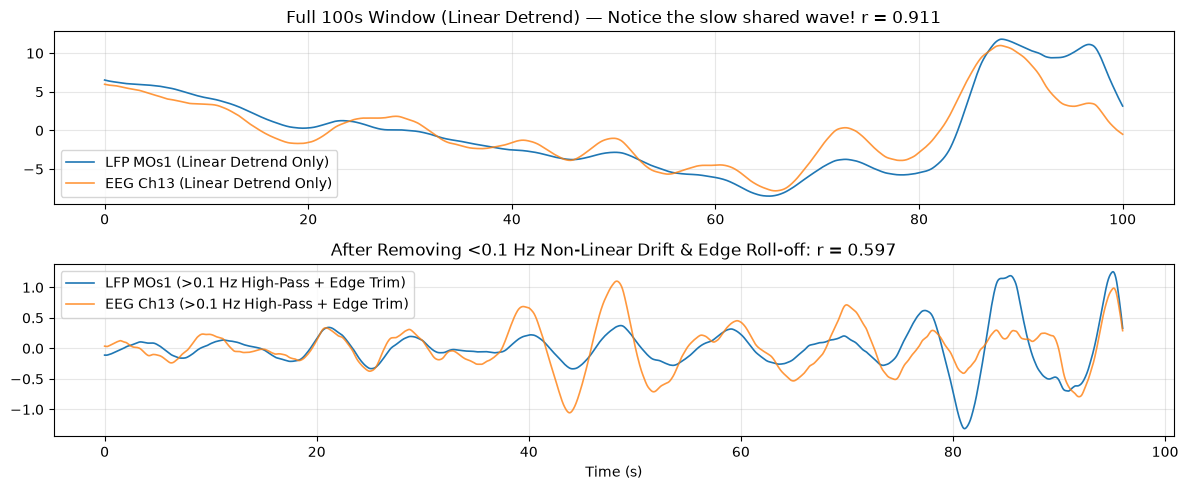


=== AFTER REMOVING <0.1 Hz DRIFT & FILTER EDGE ARTIFACTS ===
LFP_Layer   EEG_Target  r_HP  95%_Noise_Floor  N_eff  p_surr  p_Neff
     MOs1 EEG_Ch13_MOs 0.597            0.545     20  0.0200  0.0047
     MOs1 EEG_Ch7_VISa 0.561            0.553     19  0.0460  0.0114
   MOs2/3 EEG_Ch13_MOs 0.546            0.498     20  0.0250  0.0127
   MOs2/3 EEG_Ch7_VISa 0.501            0.488     19  0.0460  0.0281
     MOs5 EEG_Ch13_MOs 0.329            0.467     18  0.2068  0.1855
     MOs5 EEG_Ch7_VISa 0.303            0.493     18  0.2717  0.2325
    MOs6a EEG_Ch13_MOs 0.375            0.442     19  0.0999  0.1147
    MOs6a EEG_Ch7_VISa 0.406            0.434     19  0.0589  0.0898

=== SPATIAL SPECIFICITY CHECK: CORRELATING LFP WITH LOCAL FRONTAL (Ch13 - Ch7) ===
Layer MOs1   vs (Ch13 - Ch7) | r = -0.084 | Noise Floor = 0.557 | N_eff = 17 | p_Neff = 0.7510
Layer MOs2/3 vs (Ch13 - Ch7) | r = -0.018 | Noise Floor = 0.551 | N_eff = 16 | p_Neff = 0.9468
Layer MOs5   vs (Ch13 - Ch7) | r = +0.028 |

In [9]:
import numpy as np
import pandas as pd
from scipy.signal import butter, filtfilt, detrend
import matplotlib.pyplot as plt

def highpass_projection(x, fs=250.0, cutoff_hz=0.1, order=4):
    """Removes non-linear slow baseline drift (< 0.1 Hz / > 10s period) and edge roll-offs."""
    sos = butter(order, cutoff_hz, btype='highpass', fs=fs, output='sos')
    # Trim 2 seconds (500 samples) off each edge after filtering to kill boundary transients
    x_filt = filtfilt(butter(order, cutoff_hz, btype='highpass', fs=fs)[0],
                      butter(order, cutoff_hz, btype='highpass', fs=fs)[1], x)
    trim = int(2.0 * fs)
    return x_filt[trim:-trim]

# 1. Inspect what the raw vs detrended vs high-pass projections actually look like for MOs1 -> Ch13
lfp_m1, eeg_m1 = projections_cache[("MOs1", "EEG_Ch13_MOs")]
lfp_hp = highpass_projection(lfp_m1, fs=fs, cutoff_hz=0.1)
eeg_hp = highpass_projection(eeg_m1, fs=fs, cutoff_hz=0.1)

fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=False)
t_full = np.arange(len(lfp_m1)) / fs
axes[0].plot(t_full, lfp_m1, label="LFP MOs1 (Linear Detrend Only)", lw=1.2)
axes[0].plot(t_full, eeg_m1, label="EEG Ch13 (Linear Detrend Only)", lw=1.2, alpha=0.8)
axes[0].set_title(f"Full 100s Window (Linear Detrend) — Notice the slow shared wave! r = {np.corrcoef(lfp_m1, eeg_m1)[0,1]:.3f}")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

t_hp = np.arange(len(lfp_hp)) / fs
axes[1].plot(t_hp, lfp_hp, label="LFP MOs1 (>0.1 Hz High-Pass + Edge Trim)", lw=1.2)
axes[1].plot(t_hp, eeg_hp, label="EEG Ch13 (>0.1 Hz High-Pass + Edge Trim)", lw=1.2, alpha=0.8)
axes[1].set_title(f"After Removing <0.1 Hz Non-Linear Drift & Edge Roll-off: r = {np.corrcoef(lfp_hp, eeg_hp)[0,1]:.3f}")
axes[1].set_xlabel("Time (s)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 2. Re-run the Statistical Table on High-Pass (>0.1 Hz) + Edge-Trimmed Projections
clean_records = []
hp_cache = {}

for (layer, eeg_name), (p_lfp, p_eeg) in projections_cache.items():
    p_lfp_hp = highpass_projection(p_lfp, fs=fs, cutoff_hz=0.1)
    p_eeg_hp = highpass_projection(p_eeg, fs=fs, cutoff_hz=0.1)
    hp_cache[(layer, eeg_name)] = (p_lfp_hp, p_eeg_hp)
    
    r_obs, nf_95, p_surr, n_eff, p_neff = test_signal_vs_noise(p_lfp_hp, p_eeg_hp, fs=fs)
    clean_records.append({
        "LFP_Layer": layer,
        "EEG_Target": eeg_name,
        "r_HP": round(r_obs, 3),
        "95%_Noise_Floor": round(nf_95, 3),
        "N_eff": int(round(n_eff)),
        "p_surr": round(p_surr, 4),
        "p_Neff": round(p_neff, 4)
    })

df_clean = pd.DataFrame(clean_records)
print("\n=== AFTER REMOVING <0.1 Hz DRIFT & FILTER EDGE ARTIFACTS ===")
print(df_clean.to_string(index=False))

# 3. Check Spatial Specificity: Local Frontal Difference (Ch13 - Ch7)
print("\n=== SPATIAL SPECIFICITY CHECK: CORRELATING LFP WITH LOCAL FRONTAL (Ch13 - Ch7) ===")
for layer in mos_layers:
    if (layer, "EEG_Ch13_MOs") in hp_cache and (layer, "EEG_Ch7_VISa") in hp_cache:
        lfp_trace, eeg_ch13 = hp_cache[(layer, "EEG_Ch13_MOs")]
        _, eeg_ch7 = hp_cache[(layer, "EEG_Ch7_VISa")]
        
        # Local dipole difference (cancels shared reference & global movement artifact)
        eeg_local_diff = eeg_ch13 - eeg_ch7
        r_diff, nf_diff, p_s, n_e, p_n = test_signal_vs_noise(lfp_trace, eeg_local_diff, fs=fs)
        print(f"Layer {layer:<6} vs (Ch13 - Ch7) | r = {r_diff:+.3f} | Noise Floor = {nf_diff:.3f} | N_eff = {int(n_e)} | p_Neff = {p_n:.4f}")

In [10]:
import numpy as np
import pandas as pd

# 1. Check how identical EEG Ch 13 and Ch 7 are in raw voltage vs projected envelope
raw_r_eeg = np.corrcoef(awake_eeg[:, 13], awake_eeg[:, 7])[0, 1]
proj_r_eeg = np.corrcoef(hp_cache[("MOs1", "EEG_Ch13_MOs")][1], hp_cache[("MOs1", "EEG_Ch7_VISa")][1])[0, 1]
print(f"1. EEG Ch13 vs Ch7 Raw Voltage Correlation:       r = {raw_r_eeg:.3f}")
print(f"   EEG Ch13 vs Ch7 Motif-Projected Correlation:   r = {proj_r_eeg:.3f}")

# 2. TRUE Bipolar EEG Voltage: Subtract raw voltages (V_Ch13 - V_Ch7) BEFORE computing envelopes!
v_eeg_bipolar = awake_eeg[:, 13] - awake_eeg[:, 7]
env_eeg_bipolar = get_clean_envelopes(v_eeg_bipolar, fs, BANDS)

print("\n2. TRUE BIPOLAR EEG VOLTAGE (V_Ch13 - V_Ch7 computed BEFORE smooth_env):")
for layer in mos_layers:
    ch_indices = np.where((lfp_locs == layer) & (lfp_probes == "probeF"))[0]
    rep_ch = ch_indices[len(ch_indices) // 2]
    
    env_lfp = get_clean_envelopes(awake_lfp[:, rep_ch], fs, BANDS)
    valid_lfp = np.all(np.isfinite(env_lfp), axis=0)
    res_lfp = get_motifs([env_lfp[:, valid_lfp]], fs, n_null=20, seed=0, verbose=False)
    if res_lfp.n_motifs == 0:
        continue
        
    min_len = min(env_lfp.shape[1], env_eeg_bipolar.shape[1])
    valid = np.all(np.isfinite(env_lfp[:, :min_len]), axis=0) & np.all(np.isfinite(env_eeg_bipolar[:, :min_len]), axis=0)
    
    proj_lfp_hp = highpass_projection(compute_motif_projections(env_lfp[:, :min_len][:, valid], res_lfp.motifs)[0], fs=fs)
    proj_bip_hp = highpass_projection(compute_motif_projections(env_eeg_bipolar[:, :min_len][:, valid], res_lfp.motifs)[0], fs=fs)
    
    r_obs, nf_95, p_surr, n_eff, p_neff = test_signal_vs_noise(proj_lfp_hp, proj_bip_hp, fs=fs)
    print(f"   LFP {layer:<6} vs Bipolar EEG | r = {r_obs:+.3f} | 95% Noise Floor = {nf_95:.3f} | p_surr = {p_surr:.4f} | p_Neff = {p_neff:.4f}")

# 3. Inspect the Motif 1 frequency weights for MOs1 vs MOs5
print("\n3. WHAT IS MOTIF 1 ACTUALLY MEASURING? (Frequency Band Weights):")
for layer in ["MOs1", "MOs5"]:
    ch_indices = np.where((lfp_locs == layer) & (lfp_probes == "probeF"))[0]
    rep_ch = ch_indices[len(ch_indices) // 2]
    env_lfp = get_clean_envelopes(awake_lfp[:, rep_ch], fs, BANDS)
    res_lfp = get_motifs([env_lfp[:, np.all(np.isfinite(env_lfp), axis=0)]], fs, n_null=20, seed=0, verbose=False)
    weights = np.round(res_lfp.motifs[:, 0], 2)
    print(f"   {layer:<5} Motif 1 (+) weights across {len(BANDS)} bands: {weights}")

1. EEG Ch13 vs Ch7 Raw Voltage Correlation:       r = 0.986
   EEG Ch13 vs Ch7 Motif-Projected Correlation:   r = 0.973

2. TRUE BIPOLAR EEG VOLTAGE (V_Ch13 - V_Ch7 computed BEFORE smooth_env):
   LFP MOs1   vs Bipolar EEG | r = +0.074 | 95% Noise Floor = 0.525 | p_surr = 0.7952 | p_Neff = 0.7790
   LFP MOs2/3 vs Bipolar EEG | r = -0.078 | 95% Noise Floor = 0.524 | p_surr = 0.8172 | p_Neff = 0.7723
   LFP MOs5   vs Bipolar EEG | r = -0.013 | 95% Noise Floor = 0.561 | p_surr = 0.9640 | p_Neff = 0.9628
   LFP MOs6a  vs Bipolar EEG | r = +0.135 | 95% Noise Floor = 0.599 | p_surr = 0.7023 | p_Neff = 0.6155

3. WHAT IS MOTIF 1 ACTUALLY MEASURING? (Frequency Band Weights):
   MOs1  Motif 1 (+) weights across 76 bands: [ 0.72  0.61 -0.12 -0.44 -0.1   0.35  0.78  0.85  0.85  0.87  0.85  0.74
  0.76  0.72  0.78  0.78  0.83  0.61  0.59  0.85  0.78  0.81  0.74  0.78
  0.81  0.87  0.78  0.83  0.83  0.85  0.85  0.89  0.85  0.83  0.74  0.78
  0.83  0.89  0.87  0.85  0.81  0.89  0.85  0.76  0.83  0.8

In [11]:
import numpy as np
import pandas as pd
from scipy.signal import butter, filtfilt

# -------------------------------------------------------------------------
# 1. REMOVE COMMON-MODE REFERENCE FROM BOTH EEG AND LFP (CAR)
# -------------------------------------------------------------------------
# Common Average Reference (CAR) across all EEG channels
eeg_car = awake_eeg - np.median(awake_eeg, axis=1, keepdims=True)

# Common Average Reference (CAR) across all probeF MOs LFP channels
mos_all_idx = np.where([loc.startswith("MOs") and p == "probeF" for loc, p in zip(lfp_locs, lfp_probes)])[0]
lfp_mos_median = np.median(awake_lfp[:, mos_all_idx], axis=1, keepdims=True)
lfp_car = awake_lfp - lfp_mos_median

# Verify that Ch 13 and Ch 7 are no longer identical (r=0.986) after CAR!
r_eeg_after_car = np.corrcoef(eeg_car[:, 13], eeg_car[:, 7])[0, 1]
print(f"EEG Ch13 vs Ch7 Raw Voltage Correlation AFTER CAR: r = {r_eeg_after_car:+.3f} (was +0.986)\n")

# -------------------------------------------------------------------------
# 2. RE-EXTRACT MOTIFS & PROJECTIONS ON RE-REFERENCED SIGNALS
# -------------------------------------------------------------------------
eeg_car_envs = {
    "EEG_Ch13_MOs (CAR)": get_clean_envelopes(eeg_car[:, 13], fs, BANDS),
    "EEG_Ch7_VISa (CAR)": get_clean_envelopes(eeg_car[:, 7], fs, BANDS),
}

car_records = []

for layer in mos_layers:
    ch_indices = np.where((lfp_locs == layer) & (lfp_probes == "probeF"))[0]
    rep_ch = ch_indices[len(ch_indices) // 2]
    
    # Extract envelopes & motifs on CAR-cleaned LFP
    env_lfp = get_clean_envelopes(lfp_car[:, rep_ch], fs, BANDS)
    valid_lfp = np.all(np.isfinite(env_lfp), axis=0)
    res_lfp = get_motifs([env_lfp[:, valid_lfp]], fs, n_null=20, seed=0, verbose=False)
    
    if res_lfp.n_motifs == 0:
        print(f"Layer {layer}: No significant local motifs found after CAR.")
        continue
        
    for eeg_name, env_eeg in eeg_car_envs.items():
        min_len = min(env_lfp.shape[1], env_eeg.shape[1])
        valid = np.all(np.isfinite(env_lfp[:, :min_len]), axis=0) & np.all(np.isfinite(env_eeg[:, :min_len]), axis=0)
        
        proj_lfp_hp = highpass_projection(compute_motif_projections(env_lfp[:, :min_len][:, valid], res_lfp.motifs)[0], fs=fs)
        proj_eeg_hp = highpass_projection(compute_motif_projections(env_eeg[:, :min_len][:, valid], res_lfp.motifs)[0], fs=fs)
        
        r_obs, nf_95, p_surr, n_eff, p_neff = test_signal_vs_noise(proj_lfp_hp, proj_eeg_hp, fs=fs)
        
        car_records.append({
            "LFP_Layer": layer,
            "EEG_Target": eeg_name,
            "r_CAR": round(r_obs, 3),
            "95%_Noise_Floor": round(nf_95, 3),
            "N_eff": int(round(n_eff)),
            "p_surr": round(p_surr, 4),
            "p_Neff": round(p_neff, 4)
        })

df_car = pd.DataFrame(car_records)
print("=== SIGNAL VS. NOISE AFTER COMMON AVERAGE REFERENCING (CAR) ===")
if len(df_car) > 0:
    print(df_car.to_string(index=False))

EEG Ch13 vs Ch7 Raw Voltage Correlation AFTER CAR: r = +0.838 (was +0.986)

Layer MOs1: No significant local motifs found after CAR.
Layer MOs5: No significant local motifs found after CAR.
=== SIGNAL VS. NOISE AFTER COMMON AVERAGE REFERENCING (CAR) ===
LFP_Layer         EEG_Target  r_CAR  95%_Noise_Floor  N_eff  p_surr  p_Neff
   MOs2/3 EEG_Ch13_MOs (CAR)  0.398            0.444     19  0.0749  0.0954
   MOs2/3 EEG_Ch7_VISa (CAR)  0.181            0.409     17  0.2707  0.4944
    MOs6a EEG_Ch13_MOs (CAR)  0.084            0.490     20  0.8152  0.7309
    MOs6a EEG_Ch7_VISa (CAR) -0.148            0.491     19  0.6384  0.5496


In [12]:
import numpy as np
import pandas as pd

# -------------------------------------------------------------------------
# 1. BETTER LFP REFERENCING: Use non-MOs (subcortical/other) channels on probeF
#    so we don't subtract MOs's own biological rhythm from itself!
# -------------------------------------------------------------------------
probeF_all_idx = np.where(lfp_probes == "probeF")[0]
non_mos_probeF_idx = np.where((lfp_probes == "probeF") & (~np.char.startswith(lfp_locs, "MOs")))[0]

if len(non_mos_probeF_idx) > 5:
    print(f"Referencing MOs LFP against {len(non_mos_probeF_idx)} non-MOs channels on probeF...")
    lfp_ref = np.median(awake_lfp[:, non_mos_probeF_idx], axis=1, keepdims=True)
else:
    print(f"Referencing MOs LFP against all {len(probeF_all_idx)} channels on probeF...")
    lfp_ref = np.median(awake_lfp[:, probeF_all_idx], axis=1, keepdims=True)

lfp_clean_ref = awake_lfp - lfp_ref
eeg_car = awake_eeg - np.median(awake_eeg, axis=1, keepdims=True)

eeg_car_envs = {
    "EEG_Ch13_MOs (CAR)": get_clean_envelopes(eeg_car[:, 13], fs, BANDS),
    "EEG_Ch7_VISa (CAR)": get_clean_envelopes(eeg_car[:, 7], fs, BANDS),
}

car_records_v2 = []
car_proj_cache = {}

for layer in mos_layers:
    ch_indices = np.where((lfp_locs == layer) & (lfp_probes == "probeF"))[0]
    rep_ch = ch_indices[len(ch_indices) // 2]
    
    env_lfp = get_clean_envelopes(lfp_clean_ref[:, rep_ch], fs, BANDS)
    valid_lfp = np.all(np.isfinite(env_lfp), axis=0)
    res_lfp = get_motifs([env_lfp[:, valid_lfp]], fs, n_null=20, seed=0, verbose=False)
    
    if res_lfp.n_motifs == 0:
        print(f"Layer {layer} (Ch {rep_ch}): 0 motifs found.")
        continue
        
    for eeg_name, env_eeg in eeg_car_envs.items():
        min_len = min(env_lfp.shape[1], env_eeg.shape[1])
        valid = np.all(np.isfinite(env_lfp[:, :min_len]), axis=0) & np.all(np.isfinite(env_eeg[:, :min_len]), axis=0)
        
        proj_lfp_hp = highpass_projection(compute_motif_projections(env_lfp[:, :min_len][:, valid], res_lfp.motifs)[0], fs=fs)
        proj_eeg_hp = highpass_projection(compute_motif_projections(env_eeg[:, :min_len][:, valid], res_lfp.motifs)[0], fs=fs)
        
        car_proj_cache[(layer, eeg_name)] = (proj_lfp_hp, proj_eeg_hp)
        r_obs, nf_95, p_surr, n_eff, p_neff = test_signal_vs_noise(proj_lfp_hp, proj_eeg_hp, fs=fs)
        
        car_records_v2.append({
            "LFP_Layer": layer,
            "EEG_Target": eeg_name,
            "r_CAR": round(r_obs, 3),
            "95%_Noise_Floor": round(nf_95, 3),
            "N_eff": int(round(n_eff)),
            "p_surr": round(p_surr, 4),
            "p_Neff": round(p_neff, 4)
        })

df_car_v2 = pd.DataFrame(car_records_v2)
print("\n=== TABLE 1: SIGNAL VS. NOISE (DISTAL PROBE REFERENCE + EEG CAR) ===")
print(df_car_v2.to_string(index=False))

# -------------------------------------------------------------------------
# 2. PAIRWISE HYPOTHESIS TESTS ON CAR-CLEANED PROJECTIONS
# -------------------------------------------------------------------------
print("\n=== TABLE 2: DIRECT PAIRWISE HYPOTHESIS TESTS (BLOCK BOOTSTRAP) ===")
# Test A: Regional Specificity (Does MOs2/3 correlate better with Frontal Ch13 than Visual Ch7?)
k1, k2 = ("MOs2/3", "EEG_Ch13_MOs (CAR)"), ("MOs2/3", "EEG_Ch7_VISa (CAR)")
if k1 in car_proj_cache and k2 in car_proj_cache:
    diff, (ci_l, ci_h), p_val = compare_pairs_block_bootstrap(*car_proj_cache[k1], *car_proj_cache[k2], block_sec=5.0, fs=fs)
    print(f"Regional Test [MOs2/3 -> Ch13 vs Ch7]:   Δ|r| = {diff:+.3f} | 95% CI: [{ci_l:+.3f}, {ci_h:+.3f}] | p = {p_val:.4f}")

# Test B: Depth Specificity (Does Superficial MOs2/3 beat Deep MOs6a on Frontal Ch13?)
k3, k4 = ("MOs2/3", "EEG_Ch13_MOs (CAR)"), ("MOs6a", "EEG_Ch13_MOs (CAR)")
if k3 in car_proj_cache and k4 in car_proj_cache:
    diff, (ci_l, ci_h), p_val = compare_pairs_block_bootstrap(*car_proj_cache[k3], *car_proj_cache[k4], block_sec=5.0, fs=fs)
    print(f"Depth Test    [MOs2/3 vs MOs6a on Ch13]: Δ|r| = {diff:+.3f} | 95% CI: [{ci_l:+.3f}, {ci_h:+.3f}] | p = {p_val:.4f}")

Referencing MOs LFP against 17 non-MOs channels on probeF...
Layer MOs1 (Ch 169): 0 motifs found.
Layer MOs6a (Ch 143): 0 motifs found.

=== TABLE 1: SIGNAL VS. NOISE (DISTAL PROBE REFERENCE + EEG CAR) ===
LFP_Layer         EEG_Target  r_CAR  95%_Noise_Floor  N_eff  p_surr  p_Neff
   MOs2/3 EEG_Ch13_MOs (CAR)  0.188            0.535     19  0.5105  0.4511
   MOs2/3 EEG_Ch7_VISa (CAR) -0.001            0.500     17  0.9960  0.9967
     MOs5 EEG_Ch13_MOs (CAR)  0.325            0.438     23  0.1029  0.1319
     MOs5 EEG_Ch7_VISa (CAR)  0.278            0.363     22  0.2098  0.2190

=== TABLE 2: DIRECT PAIRWISE HYPOTHESIS TESTS (BLOCK BOOTSTRAP) ===
Regional Test [MOs2/3 -> Ch13 vs Ch7]:   Δ|r| = +0.187 | 95% CI: [-0.177, +0.287] | p = 0.3920


In [13]:
# Plot/print the continuous depth profile across ALL MOs channels on probeF in the 2-min file
mos_all_idx = np.where([loc.startswith("MOs") and p == "probeF" for loc, p in zip(lfp_locs, lfp_probes)])[0]

depth_profile = []
for ch in mos_all_idx:
    env_lfp = get_clean_envelopes(lfp_clean_ref[:, ch], fs, BANDS)
    valid_lfp = np.all(np.isfinite(env_lfp), axis=0)
    res_lfp = get_motifs([env_lfp[:, valid_lfp]], fs, n_null=20, seed=0, verbose=False)
    
    if res_lfp.n_motifs > 0:
        env_eeg13 = eeg_car_envs["EEG_Ch13_MOs (CAR)"]
        env_eeg7  = eeg_car_envs["EEG_Ch7_VISa (CAR)"]
        min_len = min(env_lfp.shape[1], env_eeg13.shape[1])
        valid = np.all(np.isfinite(env_lfp[:, :min_len]), axis=0) & np.all(np.isfinite(env_eeg13[:, :min_len]), axis=0)
        
        p_lfp = highpass_projection(compute_motif_projections(env_lfp[:, :min_len][:, valid], res_lfp.motifs)[0], fs=fs)
        p_e13 = highpass_projection(compute_motif_projections(env_eeg13[:, :min_len][:, valid], res_lfp.motifs)[0], fs=fs)
        p_e7  = highpass_projection(compute_motif_projections(env_eeg7[:, :min_len][:, valid], res_lfp.motifs)[0], fs=fs)
        
        r13 = np.corrcoef(p_lfp, p_e13)[0, 1]
        r7  = np.corrcoef(p_lfp, p_e7)[0, 1]
        depth_profile.append({"Ch_Idx": ch, "Layer": lfp_locs[ch], "r_Ch13_MOs": round(r13, 3), "r_Ch7_VISa": round(r7, 3), "Diff (Ch13-Ch7)": round(abs(r13)-abs(r7), 3)})

df_profile = pd.DataFrame(depth_profile)
print("\n=== FULL LAMINAR PROFILE ACROSS ALL VALID MOs CHANNELS ON PROBEF ===")
print(df_profile.to_string(index=False))
if len(df_profile) > 0:
    print("\nMean |r| by Layer:")
    print(df_profile.groupby("Layer")[["r_Ch13_MOs", "r_Ch7_VISa", "Diff (Ch13-Ch7)"]].mean())


=== FULL LAMINAR PROFILE ACROSS ALL VALID MOs CHANNELS ON PROBEF ===
 Ch_Idx  Layer  r_Ch13_MOs  r_Ch7_VISa  Diff (Ch13-Ch7)
    144  MOs6a      -0.217       0.242           -0.025
    148   MOs5       0.179       0.317           -0.138
    149   MOs5       0.392       0.237            0.156
    150   MOs5       0.122       0.154           -0.033
    151   MOs5       0.141       0.116            0.025
    152   MOs5       0.383       0.418           -0.035
    153   MOs5       0.325       0.278            0.047
    154   MOs5       0.427       0.345            0.083
    155   MOs5       0.527       0.148            0.379
    156   MOs5       0.625       0.200            0.424
    157   MOs5       0.610       0.254            0.357
    158   MOs5       0.579       0.355            0.224
    159 MOs2/3       0.505       0.094            0.411
    160 MOs2/3       0.502       0.173            0.329
    161 MOs2/3       0.309       0.000            0.309
    162 MOs2/3       0.363       0

In [15]:
# Test the Upper L5 / Lower L2/3 "Sweet Spot" (Ch 156 & Ch 159) against Noise, VISa (Ch 7), and MOs1 (Ch 170)
sweet_spot_channels = [156, 157, 159, 160, 168, 170, 148]
spot_cache = {}
spot_rows = []

for ch in sweet_spot_channels:
    layer = lfp_locs[ch]
    env_lfp = get_clean_envelopes(lfp_clean_ref[:, ch], fs, BANDS)
    valid_lfp = np.all(np.isfinite(env_lfp), axis=0)
    res_lfp = get_motifs([env_lfp[:, valid_lfp]], fs, n_null=20, seed=0, verbose=False)
    
    if res_lfp.n_motifs == 0:
        continue
        
    for eeg_name, env_eeg in eeg_car_envs.items():
        min_len = min(env_lfp.shape[1], env_eeg.shape[1])
        valid = np.all(np.isfinite(env_lfp[:, :min_len]), axis=0) & np.all(np.isfinite(env_eeg[:, :min_len]), axis=0)
        
        p_lfp = highpass_projection(compute_motif_projections(env_lfp[:, :min_len][:, valid], res_lfp.motifs)[0], fs=fs)
        p_eeg = highpass_projection(compute_motif_projections(env_eeg[:, :min_len][:, valid], res_lfp.motifs)[0], fs=fs)
        spot_cache[(ch, eeg_name)] = (p_lfp, p_eeg)
        
        r_obs, nf_95, p_surr, n_eff, p_neff = test_signal_vs_noise(p_lfp, p_eeg, fs=fs)
        spot_rows.append({
            "Ch_Idx": ch, "Layer": layer, "EEG": eeg_name,
            "r": round(r_obs, 3), "95%_Noise": round(nf_95, 3),
            "N_eff": int(round(n_eff)), "p_surr": round(p_surr, 4), "p_Neff": round(p_neff, 4)
        })

df_spot = pd.DataFrame(spot_rows)
print("=== 1. STATISTICAL SIGNIFICANCE OF THE LAMINAR SWEET SPOT (Ch 156-160) ===")
print(df_spot[df_spot["EEG"] == "EEG_Ch13_MOs (CAR)"].to_string(index=False))

print("\n=== 2. BLOCK-BOOTSTRAP TESTS FOR UPPER MOs5 (Ch 156) ===")
# 1. Regional Specificity: Ch 156 (MOs5) -> Frontal Ch13 vs Visual Ch7
diff_reg, ci_reg, p_reg = compare_pairs_block_bootstrap(
    *spot_cache[(156, "EEG_Ch13_MOs (CAR)")], *spot_cache[(156, "EEG_Ch7_VISa (CAR)")], block_sec=5.0, fs=fs
)
print(f"Regional [Ch156 MOs5 -> Ch13 vs Ch7]:      Δ|r| = {diff_reg:+.3f} | 95% CI: [{ci_reg[0]:+.3f}, {ci_reg[1]:+.3f}] | p = {p_reg:.4f}")

# 2. Depth Test: Upper MOs5 (Ch 156) vs Superficial MOs1 (Ch 168) on Frontal Ch13
diff_l1, ci_l1, p_l1 = compare_pairs_block_bootstrap(
    *spot_cache[(156, "EEG_Ch13_MOs (CAR)")], *spot_cache[(168, "EEG_Ch13_MOs (CAR)")], block_sec=5.0, fs=fs
)
print(f"Depth    [Ch156 MOs5 vs Ch168 MOs1]:       Δ|r| = {diff_l1:+.3f} | 95% CI: [{ci_l1[0]:+.3f}, {ci_l1[1]:+.3f}] | p = {p_l1:.4f}")

# 3. Sub-Layer Test: Upper MOs5 (Ch 156) vs Deep MOs5 (Ch 148) on Frontal Ch13
diff_sub, ci_sub, p_sub = compare_pairs_block_bootstrap(
    *spot_cache[(156, "EEG_Ch13_MOs (CAR)")], *spot_cache[(148, "EEG_Ch13_MOs (CAR)")], block_sec=5.0, fs=fs
)
print(f"SubLayer [Ch156 Upper L5 vs Ch148 Deep L5]: Δ|r| = {diff_sub:+.3f} | 95% CI: [{ci_sub[0]:+.3f}, {ci_sub[1]:+.3f}] | p = {p_sub:.4f}")

=== 1. STATISTICAL SIGNIFICANCE OF THE LAMINAR SWEET SPOT (Ch 156-160) ===
 Ch_Idx  Layer                EEG     r  95%_Noise  N_eff  p_surr  p_Neff
    156   MOs5 EEG_Ch13_MOs (CAR) 0.625      0.451     19  0.0010  0.0031
    157   MOs5 EEG_Ch13_MOs (CAR) 0.610      0.487     19  0.0010  0.0044
    159 MOs2/3 EEG_Ch13_MOs (CAR) 0.505      0.550     19  0.1259  0.0247
    160 MOs2/3 EEG_Ch13_MOs (CAR) 0.502      0.457     21  0.0010  0.0180
    168   MOs1 EEG_Ch13_MOs (CAR) 0.160      0.479     20  0.5275  0.5116
    170   MOs1 EEG_Ch13_MOs (CAR) 0.034      0.472     20  0.8841  0.8898
    148   MOs5 EEG_Ch13_MOs (CAR) 0.179      0.558     21  0.4505  0.4450

=== 2. BLOCK-BOOTSTRAP TESTS FOR UPPER MOs5 (Ch 156) ===
Regional [Ch156 MOs5 -> Ch13 vs Ch7]:      Δ|r| = +0.424 | 95% CI: [+0.112, +0.668] | p = 0.0090
Depth    [Ch156 MOs5 vs Ch168 MOs1]:       Δ|r| = +0.465 | 95% CI: [+0.298, +0.608] | p = 0.0000
SubLayer [Ch156 Upper L5 vs Ch148 Deep L5]: Δ|r| = +0.446 | 95% CI: [+0.110, +0.6